# Membrete

| | |
|---|---|
| **Autor** | Avila Larrotta |
| **Programa** | Maestría en Inteligencia Artificial |
| **Asignatura** | Computación de Alto Rendimiento (HPC) |
| **Trabajo** | Clasificación de ICTUS (derrame cerebral) con Spark MLlib sobre Hadoop HDFS |
| **Fecha de inicio** | 05/11/2026 |
| **Fecha de entrega** | 22/11/2026 |

# Contexto

El **ictus** (accidente cerebrovascular o derrame cerebral) ocurre cuando se interrumpe el flujo de sangre
hacia una parte del cerebro, por obstrucción (isquémico) o por ruptura de un vaso (hemorrágico). Según la
Organización Mundial de la Salud es una de las principales causas de muerte y de discapacidad en adultos.
Gran parte de los casos se asocia a factores de riesgo conocidos y modificables: hipertensión, enfermedad
cardiaca, glucosa elevada, obesidad y tabaquismo, además de la edad.

Identificar con anticipación a los pacientes con mayor riesgo permite priorizar el seguimiento clínico. Por eso
se plantea un problema de **clasificación binaria supervisada**: a partir de datos demográficos y clínicos,
predecir si un paciente ha sufrido un ictus (`ICTUS = 1`) o no (`ICTUS = 0`).

**Dataset.** `stroke_pyspark.csv` (Stroke Prediction Dataset), almacenado en el DataLake del clúster en
`hdfs://10.195.34.34:9000/csv/stroke_pyspark.csv`. Tiene 5 110 registros y 12 columnas: identificador, 10
variables explicativas (género, edad, hipertensión, enfermedad cardiaca, estado civil, tipo de trabajo, tipo de
residencia, nivel promedio de glucosa, IMC y hábito de fumar) y la variable objetivo `stroke`.

**Entorno HPC.** El procesamiento se hace con **Apache Spark** (PySpark) leyendo directamente desde
**Hadoop HDFS**. Las transformaciones, la imputación, la codificación y el entrenamiento de los modelos se
ejecutan como operaciones distribuidas sobre DataFrames de Spark, y los modelos se toman de la biblioteca
**MLlib** (`pyspark.ml`). Solo los resultados ya agregados se pasan a pandas para graficarlos.

**Reto principal.** La clase positiva es muy minoritaria (≈ 4.9 % de los pacientes). Un modelo que siempre
responda "No ICTUS" tendría ~95 % de exactitud sin detectar ningún caso, así que la exactitud no sirve como
métrica principal y hay que tratar el desbalance de forma explícita.

# Objetivos

### Objetivo general
Construir y evaluar, con la metodología **CRISP-DM** y Spark MLlib sobre HDFS, modelos de clasificación que
identifiquen a los pacientes con ICTUS a partir de sus variables demográficas y clínicas.

### Objetivos específicos
1. Leer el dataset desde **Hadoop HDFS** y manipularlo con DataFrames distribuidos de Spark.
2. **Conocer los datos**: estructura, tipos, calidad (nulos y categorías inconsistentes) y relación de cada
   variable con el ICTUS mediante análisis exploratorio.
3. **Preparar los datos**: corrección de tipos, limpieza, imputación del IMC por género y edad, variable
   derivada, codificación de categóricas, ensamblado y escalado de características, y tratamiento del
   desbalance de clases.
4. **Entrenar al menos cinco modelos de MLlib**: Regresión Logística, Árbol de Decisión, Random Forest,
   Gradient-Boosted Trees, Máquina de Soporte Vectorial lineal, Perceptrón Multicapa y Naive Bayes.
5. **Evaluar y comparar** los modelos con métricas adecuadas para clases desbalanceadas: *recall*,
   precisión y F1 de la clase ICTUS, especificidad, AUC-ROC y AUC-PR, además de la matriz de confusión.
6. Analizar los resultados y concluir cuál modelo conviene para el problema y por qué.

# Desarrollo y documentación

El trabajo sigue las fases de **CRISP-DM**:

| Fase CRISP-DM | Sección del cuaderno |
|---|---|
| Comprensión del negocio | Contexto y Objetivos |
| Comprensión de los datos | 1. Conocimiento de datos |
| Preparación de los datos | 2. Preparación de datos |
| Modelado | 3. Modelos de MLlib |
| Evaluación | 4. Evaluación de modelos y 5. Análisis de resultados |
| Despliegue (recomendación) | 6. Conclusiones |

## 1. Conocimiento de datos
### 1.1 Bibliotecas y sesión de Spark

In [1]:
#Importar bibliotecas generales
import numpy as np                               # Biblioteca para matemática y algebra lineal
import seaborn as sns                            # Biblioteca para estadística y gráficas
import matplotlib.pyplot as plt                  # Biblioteca que se usa para dar formato a las graficas
import pandas as pd                              # Biblioteca para generar objetos de tipo DataFrame (No big data)

In [2]:
#Se importan las bibliotecas para PySpark
import findspark                                   # Permite cargar la ruta de Spark
findspark.init("/mnt/sda1/Cluster/Spark/")         # Ruta de spark lista

from pyspark import SparkConf, SparkContext        # Configuración global y punto de entrada para computación distribuida con Conjuntos de Datos Distribuidos Resilientes
from pyspark.sql import functions as F             # Funciones integradas para transformaciones, agregaciones y cálculo en columnas
from pyspark.sql import SQLContext, SparkSession   # SparkSession es el punto de entrada unificado moderno; SQLContext es la interfaz legacy
from pyspark.sql.types import *                    # Tipos de datos para definir esquemas estructurados de DataFrames (StringType, IntegerType, etc.)

In [3]:
configura = SparkConf().set("spark.ui.port","37001")                          # Configuración de Spark: define el puerto de la interfaz web (Spark UI) en 37001 dada la asignación en clase
configura.setAppName("AvilaIctusSpark")                                     # Asigna el nombre de la aplicación, visible en la Spark UI y en el gestor del cluster

sparkAvila = SparkSession.builder.config(conf=configura).getOrCreate()        # Crea la sesión de Spark con la configuración anterior, o reutiliza una que ya exista
SQLContext(sparkContext=sparkAvila.sparkContext, sparkSession=sparkAvila)     # Crea el contexto SQL legacy a partir del SparkContext de la sesión (compatibilidad con código antiguo)

print("Sesion creada el 05 de noviembre por Avila")                             # Mensaje de confirmación de que la sesión se creó
sparkAvila                                                                    # Muestra la información de la sesión (versión, master, nombre de la app y enlace a la UI)

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


Sesion creada el 05 de noviembre por Avila


### 1.2 Carga del dataset desde Hadoop HDFS

In [4]:
# Se consulta que hay dentro de Hadoop HDFS
!/mnt/sda1/Cluster/Hadoop/bin/hadoop fs -ls /

Found 13 items
drwxr-xr-x   - sistemas  supergroup          0 2025-10-31 15:50 /DistriFlipa
drwxrwxrwx   - sistemas  supergroup          0 2026-10-30 08:30 /FAC_Dataset
drwxrwxrwx   - sistemas  supergroup          0 2026-11-19 17:34 /Formatos1055
drwxrwxrwx   - sistemas  supergroup          0 2026-11-19 17:13 /Formatos1255
drwxrwxrwx   - sistemas  supergroup          0 2026-11-12 18:15 /FormatosHPC
drwxr-xr-x   - seguridad supergroup          0 2026-11-14 23:34 /benchmark
drwxr-xr-x   - sistemas  supergroup          0 2026-11-12 12:15 /csv
drwxr-xr-x   - sistemas  supergroup          0 2026-11-17 15:59 /images
drwxr-xr-x   - sistemas  supergroup          0 2025-09-02 13:23 /json
drwxr-xr-x   - sistemas  supergroup          0 2025-09-02 16:56 /parquet
drwxrwxr-x+  - userpm025 supergroup          0 2025-10-25 17:51 /pm25
drwxrwxrwx   - sistemas  supergroup          0 2026-11-13 16:19 /seguridad
drwxr-xr-x   - usuario22 usuario22           0 2026-04-15 15:19 /user22


In [5]:
# Se consulta que hay dentro de Hadoop HDFS
!/mnt/sda1/Cluster/Hadoop/bin/hadoop fs -ls /csv

Found 11 items
drwxr-xr-x   - sistemas supergroup          0 2026-10-23 13:39 /csv/BankMarketing
-rw-r--r--   2 sistemas supergroup     977501 2026-03-10 15:27 /csv/CustomerChurn.csv
-rw-r--r--   2 sistemas supergroup      40868 2025-07-07 15:41 /csv/Fortune500USCompanies.csv
drwxr-xr-x   - sistemas supergroup          0 2025-10-16 14:17 /csv/auxiliar
drwxr-xr-x   - sistemas supergroup          0 2026-11-12 12:16 /csv/calidadAgua
-rw-r--r--   2 sistemas supergroup      34635 2025-09-02 13:22 /csv/jugadores.csv
-rw-r--r--   2 sistemas supergroup    1082023 2025-09-02 13:22 /csv/resultados_futbol.csv
-rw-r--r--   2 sistemas supergroup     316971 2025-06-10 09:11 /csv/stroke_pyspark.csv
drwxr-xr-x   - sistemas supergroup          0 2025-06-18 15:36 /csv/taxi
drwxr-xr-x   - sistemas supergroup          0 2026-04-23 15:56 /csv/titanic
-rw-r--r--   2 sistemas supergroup      84199 2026-04-23 17:11 /csv/winequality-red.csv


In [6]:
### Se requiere crear un objeto de tipo DataFrame con el CSV
# Se carga el dataset del Ictus desde el DataLake
urlAvila = "hdfs://10.195.34.34:9000/csv/stroke_pyspark.csv"
df00 = sparkAvila.read.format("csv").option("header", "true").load(urlAvila)

# Se ven los 5 primeros
df00.show(5)

[Stage 1:>                                                          (0 + 1) / 1]

+-----+------+---+------------+-------------+------------+-------------+--------------+-----------------+----+---------------+------+
|   id|gender|age|hypertension|heart_disease|ever_married|    work_type|Residence_type|avg_glucose_level| bmi| smoking_status|stroke|
+-----+------+---+------------+-------------+------------+-------------+--------------+-----------------+----+---------------+------+
| 9046|  Male| 67|           0|            1|         Yes|      Private|         Urban|           228.69|36.6|formerly smoked|     1|
|51676|Female| 61|           0|            0|         Yes|Self-employed|         Rural|           202.21| N/A|   never smoked|     1|
|31112|  Male| 80|           0|            1|         Yes|      Private|         Rural|           105.92|32.5|   never smoked|     1|
|60182|Female| 49|           0|            0|         Yes|      Private|         Urban|           171.23|34.4|         smokes|     1|
| 1665|Female| 79|           1|            0|         Yes|Self

### 1.3 Diccionario de datos

Se renombran las columnas al español. Significado de cada variable:

| Original | Nuevo nombre | Tipo | Descripción |
|---|---|---|---|
| id | id | Entero | Identificador del paciente (no aporta información predictiva) |
| gender | Genero | Categórica | Male / Female / Other |
| age | Edad | Numérica | Edad en años |
| hypertension | Hipertension | Binaria | 1 si el paciente es hipertenso |
| heart_disease | EnfCardiaca | Binaria | 1 si tiene alguna enfermedad cardiaca |
| ever_married | EstadoCivil | Categórica | Si se ha casado alguna vez (Yes / No) |
| work_type | TipoTrabajo | Categórica | Private, Self-employed, Govt_job, children, Never_worked |
| Residence_type | TipoResidencia | Categórica | Urban / Rural |
| avg_glucose_level | PromNivelGlucosa | Numérica | Nivel promedio de glucosa en sangre (mg/dL) |
| bmi | IMC | Numérica | Índice de masa corporal (kg/m²) |
| smoking_status | Fumador | Categórica | never smoked, formerly smoked, smokes, Unknown |
| stroke | ICTUS | Binaria (objetivo) | 1 si el paciente sufrió un ictus |

In [7]:
# Se requiere cambiar los nombres
df00.columns

['id',
 'gender',
 'age',
 'hypertension',
 'heart_disease',
 'ever_married',
 'work_type',
 'Residence_type',
 'avg_glucose_level',
 'bmi',
 'smoking_status',
 'stroke']

In [8]:
# Nuevos nombres
nuevosNombres = ['id', 'Genero', 'Edad', 'Hipertension', 'EnfCardiaca', 'EstadoCivil',
 'TipoTrabajo',
 'TipoResidencia',
 'PromNivelGlucosa',
 'IMC',
 'Fumador',
 'ICTUS']

# Se hace el cambio con nueva version
df01 = df00
for antes, nuevos in zip(df00.columns, nuevosNombres):
    df01 = df01.withColumnRenamed(antes, nuevos)

# Se verifica
df01.columns

['id',
 'Genero',
 'Edad',
 'Hipertension',
 'EnfCardiaca',
 'EstadoCivil',
 'TipoTrabajo',
 'TipoResidencia',
 'PromNivelGlucosa',
 'IMC',
 'Fumador',
 'ICTUS']

In [9]:
#Se requiere el topo de datos y la coherencia de datos
df01.printSchema()

root
 |-- id: string (nullable = true)
 |-- Genero: string (nullable = true)
 |-- Edad: string (nullable = true)
 |-- Hipertension: string (nullable = true)
 |-- EnfCardiaca: string (nullable = true)
 |-- EstadoCivil: string (nullable = true)
 |-- TipoTrabajo: string (nullable = true)
 |-- TipoResidencia: string (nullable = true)
 |-- PromNivelGlucosa: string (nullable = true)
 |-- IMC: string (nullable = true)
 |-- Fumador: string (nullable = true)
 |-- ICTUS: string (nullable = true)



### Se requiere que
['id',                   *entero
 'Edad',                 *entero
 'Hipertension',         *entero
 'EnfCardiaca',          *entero
 'PromNivelGlucosa',     *flotante
 'IMC',                  *flotante
 'ICTUS']                *entero

In [10]:
# Recordar cambio de version
df02 = df01.withColumn("id", df01.id.cast("int"))
df02 = df02.withColumn("Edad", df02.Edad.cast("int"))
df02 = df02.withColumn("Hipertension", df02.Hipertension.cast("int"))
df02 = df02.withColumn("EnfCardiaca", df02.EnfCardiaca.cast("int"))
df02 = df02.withColumn("PromNivelGlucosa", df02.PromNivelGlucosa.cast("float"))
df02 = df02.withColumn("IMC", df02.IMC.cast("float"))
df02 = df02.withColumn("ICTUS", df02.ICTUS.cast("int"))

## Se verifica
df02.show(5)

## Tipo de datos
df02.printSchema()

+-----+------+----+------------+-----------+-----------+-------------+--------------+----------------+----+---------------+-----+
|   id|Genero|Edad|Hipertension|EnfCardiaca|EstadoCivil|  TipoTrabajo|TipoResidencia|PromNivelGlucosa| IMC|        Fumador|ICTUS|
+-----+------+----+------------+-----------+-----------+-------------+--------------+----------------+----+---------------+-----+
| 9046|  Male|  67|           0|          1|        Yes|      Private|         Urban|          228.69|36.6|formerly smoked|    1|
|51676|Female|  61|           0|          0|        Yes|Self-employed|         Rural|          202.21|NULL|   never smoked|    1|
|31112|  Male|  80|           0|          1|        Yes|      Private|         Rural|          105.92|32.5|   never smoked|    1|
|60182|Female|  49|           0|          0|        Yes|      Private|         Urban|          171.23|34.4|         smokes|    1|
| 1665|Female|  79|           1|          0|        Yes|Self-employed|         Rural|     

### 1.4 Calidad de los datos: valores nulos y categorías

In [11]:
# Cuantificar la cantidad de datos nulos
df02.select([F.count(F.when(F.isnan(c) | F.col(c).isNull(), c)).alias(c) for c in df02.columns]).show() 

+---+------+----+------------+-----------+-----------+-----------+--------------+----------------+---+-------+-----+
| id|Genero|Edad|Hipertension|EnfCardiaca|EstadoCivil|TipoTrabajo|TipoResidencia|PromNivelGlucosa|IMC|Fumador|ICTUS|
+---+------+----+------------+-----------+-----------+-----------+--------------+----------------+---+-------+-----+
|  0|     0|   0|           0|          0|          0|          0|             0|               0|201|      0|    0|
+---+------+----+------------+-----------+-----------+-----------+--------------+----------------+---+-------+-----+



In [12]:
print(len(df02.columns))
print(df02.count())

12
5110


# Observacion
    - La idea es que los valores nulos del IMC sean transformados
    - dado que la proporcion es baja de datos nulos es crear la sensibilidad para NO ELIMINARLOS

In [13]:
# Se revisa las categorias en el DataFrame

df02.groupby(["Genero"]).count().show()

+------+-----+
|Genero|count|
+------+-----+
|Female| 2994|
| Other|    1|
|  Male| 2115|
+------+-----+



In [ ]:
### Para ser coherente frente al estudio medico objetico, se elimina el Other

df03 = df02.where(F.col("Genero") != "Other")

### Se verifica que quedaron 2 generos
df03.groupby(["Genero"]).count().show()

In [15]:
# Se revisa las categorias en el DataFrame, en este caso EstadoCivil

df02.groupby(["EstadoCivil"]).count().show()

+-----------+-----+
|EstadoCivil|count|
+-----------+-----+
|         No| 1757|
|        Yes| 3353|
+-----------+-----+



In [16]:
# Se revisa las categorias en el DataFrame, en este caso TipoDeTrabajo

df02.groupby(["TipoTrabajo"]).count().show()

+-------------+-----+
|  TipoTrabajo|count|
+-------------+-----+
| Never_worked|   22|
|Self-employed|  819|
|      Private| 2925|
|     children|  687|
|     Govt_job|  657|
+-------------+-----+



In [17]:
# Se revisa las categorias en el DataFrame, en este caso TipoResidencia

df02.groupby(["TipoResidencia"]).count().show()

+--------------+-----+
|TipoResidencia|count|
+--------------+-----+
|         Urban| 2596|
|         Rural| 2514|
+--------------+-----+



In [18]:
# Se revisa las categorias en el DataFrame, en este caso Fumador

df02.groupby(["Fumador"]).count().show()

+---------------+-----+
|        Fumador|count|
+---------------+-----+
|         smokes|  789|
|        Unknown| 1544|
|   never smoked| 1892|
|formerly smoked|  885|
+---------------+-----+



### 1.5 Distribución de la variable objetivo

In [ ]:
### Se cuantifica cuántos pacientes tienen y no tienen ICTUS
df03.groupBy('ICTUS').count() \
    .withColumn('Porcentaje', F.round(F.col('count') / F.lit(df03.count()) * 100, 2)) \
    .orderBy('ICTUS').show()

**Observación.** Solo ≈ 249 pacientes (≈ 4.9 %) tienen ICTUS, es decir, hay unos 19 pacientes sanos por
cada caso positivo. Este **desbalance severo** condiciona la preparación y la evaluación: hay que usar
métricas centradas en la clase 1 y aplicar alguna técnica de balanceo al entrenar.

### 1.6 Tratamiento de los valores nulos del IMC

La imputación es parte de la preparación de datos, pero se hace aquí para que el análisis gráfico de la
sección 1.7 se haga con el IMC completo.

### Estrategia para hacer imputacion sobre los datos nulos
- Promedio por edad cada 10 años y por genero
- Se sustituye los nulos encontrados en la anterior categoria

In [19]:
### Promedio Female entre 00 años y 10 años
avgF10  = df03.where((F.col("Genero") == F.lit("Female")) & (F.col("Edad") < 10)).select(F.mean(F.col("IMC"))).collect()
avgF20  = df03.where((F.col("Genero") == F.lit("Female")) & (F.col("Edad") >= 10) & (F.col("Edad") < 20)).select(F.mean(F.col("IMC"))).collect()
avgF30  = df03.where((F.col("Genero") == F.lit("Female")) & (F.col("Edad") >= 20) & (F.col("Edad") < 30)).select(F.mean(F.col("IMC"))).collect()
avgF40  = df03.where((F.col("Genero") == F.lit("Female")) & (F.col("Edad") >= 30) & (F.col("Edad") < 40)).select(F.mean(F.col("IMC"))).collect()
avgF50  = df03.where((F.col("Genero") == F.lit("Female")) & (F.col("Edad") >= 40) & (F.col("Edad") < 50)).select(F.mean(F.col("IMC"))).collect()
avgF60  = df03.where((F.col("Genero") == F.lit("Female")) & (F.col("Edad") >= 50) & (F.col("Edad") < 60)).select(F.mean(F.col("IMC"))).collect()
avgF70  = df03.where((F.col("Genero") == F.lit("Female")) & (F.col("Edad") >= 60) & (F.col("Edad") < 70)).select(F.mean(F.col("IMC"))).collect()
avgF80  = df03.where((F.col("Genero") == F.lit("Female")) & (F.col("Edad") >= 70) & (F.col("Edad") < 80)).select(F.mean(F.col("IMC"))).collect()
avgF90  = df03.where((F.col("Genero") == F.lit("Female")) & (F.col("Edad") >= 80) & (F.col("Edad") < 90)).select(F.mean(F.col("IMC"))).collect()

print(f"Promedio de IMC en mujeres menores de 10 años es: {round(avgF10[0][0], 2)}")
print(f"Promedio de IMC en mujeres de 10 a 19 años es: {round(avgF20[0][0], 2)}")
print(f"Promedio de IMC en mujeres de 20 a 29 años es: {round(avgF30[0][0], 2)}")
print(f"Promedio de IMC en mujeres de 30 a 39 años es: {round(avgF40[0][0], 2)}")
print(f"Promedio de IMC en mujeres de 40 a 49 años es: {round(avgF50[0][0], 2)}")
print(f"Promedio de IMC en mujeres de 50 a 59 años es: {round(avgF60[0][0], 2)}")
print(f"Promedio de IMC en mujeres de 60 a 69 años es: {round(avgF70[0][0], 2)}")
print(f"Promedio de IMC en mujeres de 70 a 79 años es: {round(avgF80[0][0], 2)}")
print(f"Promedio de IMC en mujeres de 80 a 89 años es: {round(avgF90[0][0], 2)}")

Promedio de IMC en mujeres menores de 10 años es: 18.69
Promedio de IMC en mujeres de 10 a 19 años es: 25.2
Promedio de IMC en mujeres de 20 a 29 años es: 28.11
Promedio de IMC en mujeres de 30 a 39 años es: 31.11
Promedio de IMC en mujeres de 40 a 49 años es: 31.15
Promedio de IMC en mujeres de 50 a 59 años es: 31.65
Promedio de IMC en mujeres de 60 a 69 años es: 30.78
Promedio de IMC en mujeres de 70 a 79 años es: 29.54
Promedio de IMC en mujeres de 80 a 89 años es: 28.24


In [20]:
### IMC promedio por rangos de edad - Hombres (Male)
avgM10  = df03.where((F.col("Genero") == F.lit("Male")) & (F.col("Edad") < 10)).select(F.mean(F.col("IMC"))).collect()
avgM20  = df03.where((F.col("Genero") == F.lit("Male")) & (F.col("Edad") >= 10) & (F.col("Edad") < 20)).select(F.mean(F.col("IMC"))).collect()
avgM30  = df03.where((F.col("Genero") == F.lit("Male")) & (F.col("Edad") >= 20) & (F.col("Edad") < 30)).select(F.mean(F.col("IMC"))).collect()
avgM40  = df03.where((F.col("Genero") == F.lit("Male")) & (F.col("Edad") >= 30) & (F.col("Edad") < 40)).select(F.mean(F.col("IMC"))).collect()
avgM50  = df03.where((F.col("Genero") == F.lit("Male")) & (F.col("Edad") >= 40) & (F.col("Edad") < 50)).select(F.mean(F.col("IMC"))).collect()
avgM60  = df03.where((F.col("Genero") == F.lit("Male")) & (F.col("Edad") >= 50) & (F.col("Edad") < 60)).select(F.mean(F.col("IMC"))).collect()
avgM70  = df03.where((F.col("Genero") == F.lit("Male")) & (F.col("Edad") >= 60) & (F.col("Edad") < 70)).select(F.mean(F.col("IMC"))).collect()
avgM80  = df03.where((F.col("Genero") == F.lit("Male")) & (F.col("Edad") >= 70) & (F.col("Edad") < 80)).select(F.mean(F.col("IMC"))).collect()
avgM90  = df03.where((F.col("Genero") == F.lit("Male")) & (F.col("Edad") >= 80) & (F.col("Edad") < 90)).select(F.mean(F.col("IMC"))).collect()

print(f"Promedio de IMC en hombres menores de 10 años es: {round(avgM10[0][0], 2)}")
print(f"Promedio de IMC en hombres de 10 a 19 años es: {round(avgM20[0][0], 2)}")
print(f"Promedio de IMC en hombres de 20 a 29 años es: {round(avgM30[0][0], 2)}")
print(f"Promedio de IMC en hombres de 30 a 39 años es: {round(avgM40[0][0], 2)}")
print(f"Promedio de IMC en hombres de 40 a 49 años es: {round(avgM50[0][0], 2)}")
print(f"Promedio de IMC en hombres de 50 a 59 años es: {round(avgM60[0][0], 2)}")
print(f"Promedio de IMC en hombres de 60 a 69 años es: {round(avgM70[0][0], 2)}")
print(f"Promedio de IMC en hombres de 70 a 79 años es: {round(avgM80[0][0], 2)}")
print(f"Promedio de IMC en hombres de 80 a 89 años es: {round(avgM90[0][0], 2)}")

Promedio de IMC en hombres menores de 10 años es: 19.03
Promedio de IMC en hombres de 10 a 19 años es: 24.58
Promedio de IMC en hombres de 20 a 29 años es: 28.23
Promedio de IMC en hombres de 30 a 39 años es: 31.37
Promedio de IMC en hombres de 40 a 49 años es: 31.94
Promedio de IMC en hombres de 50 a 59 años es: 31.89
Promedio de IMC en hombres de 60 a 69 años es: 31.3
Promedio de IMC en hombres de 70 a 79 años es: 29.14
Promedio de IMC en hombres de 80 a 89 años es: 28.35


In [21]:
### Resultados IMC promedio por rango de edad: Hombres (M) vs Mujeres (F)
print(f"Promedio menores de 10 años en IMC: M= {round(avgM10[0][0], 2)}   ||  F= {round(avgF10[0][0], 2)}")
print(f"Promedio de 10 a 19 años en IMC:    M= {round(avgM20[0][0], 2)}   ||  F= {round(avgF20[0][0], 2)}")
print(f"Promedio de 20 a 29 años en IMC:    M= {round(avgM30[0][0], 2)}   ||  F= {round(avgF30[0][0], 2)}")
print(f"Promedio de 30 a 39 años en IMC:    M= {round(avgM40[0][0], 2)}   ||  F= {round(avgF40[0][0], 2)}")
print(f"Promedio de 40 a 49 años en IMC:    M= {round(avgM50[0][0], 2)}   ||  F= {round(avgF50[0][0], 2)}")
print(f"Promedio de 50 a 59 años en IMC:    M= {round(avgM60[0][0], 2)}   ||  F= {round(avgF60[0][0], 2)}")
print(f"Promedio de 60 a 69 años en IMC:    M= {round(avgM70[0][0], 2)}   ||  F= {round(avgF70[0][0], 2)}")
print(f"Promedio de 70 a 79 años en IMC:    M= {round(avgM80[0][0], 2)}   ||  F= {round(avgF80[0][0], 2)}")
print(f"Promedio de 80 a 89 años en IMC:    M= {round(avgM90[0][0], 2)}   ||  F= {round(avgF90[0][0], 2)}")

Promedio menores de 10 años en IMC: M= 19.03   ||  F= 18.69
Promedio de 10 a 19 años en IMC:    M= 24.58   ||  F= 25.2
Promedio de 20 a 29 años en IMC:    M= 28.23   ||  F= 28.11
Promedio de 30 a 39 años en IMC:    M= 31.37   ||  F= 31.11
Promedio de 40 a 49 años en IMC:    M= 31.94   ||  F= 31.15
Promedio de 50 a 59 años en IMC:    M= 31.89   ||  F= 31.65
Promedio de 60 a 69 años en IMC:    M= 31.3   ||  F= 30.78
Promedio de 70 a 79 años en IMC:    M= 29.14   ||  F= 29.54
Promedio de 80 a 89 años en IMC:    M= 28.35   ||  F= 28.24


# Apreciaciones

1. **Valores nulos en IMC.** De los 5 110 registros, 201 no tienen IMC (3.9 %). Es la única variable con
   datos faltantes. Eliminar esas filas reduciría el dataset y podría sesgarlo, porque se perderían pacientes
   con ICTUS, una clase que ya es minoritaria. Por eso se decide **imputarlos** en lugar de eliminarlos.

2. **Estrategia de imputación.** En lugar de usar la media global del IMC, se reemplaza cada nulo por la
   media del IMC de su mismo **género y grupo de edad**. Así el valor imputado se parece más al de personas
   con características similares, porque el IMC depende mucho de la edad.

3. **Segmentación por edad.** Se crean grupos de 10 años (0–9, 10–19, …, 80–89), con el límite inferior
   incluido y el superior excluido, para que ninguna edad quede en dos grupos. Se calcula la media por grupo
   y por género (Male/Female), lo que da 18 valores de imputación.

4. **Comportamiento del IMC por edad y género.**
   - **La edad es el factor principal:** el IMC promedio sube de ~19 en menores de 10 años a ~31–32 entre
     los 30 y 59 años (pico en 40–49 para hombres con 31.94 y en 50–59 para mujeres con 31.65), y luego
     desciende a ~28 en los mayores de 80. Es una diferencia de unos 13 puntos entre grupos.
   - **El género tiene un efecto pequeño:** la diferencia entre hombres y mujeres es menor a 0.8 puntos en
     todos los rangos (la mayor es 0.79, en 40–49 años). Aun así, es bastante consistente: los hombres
     tienen un IMC ligeramente mayor en 7 de los 9 grupos.
   - Esto confirma que segmentar por edad es lo que más mejora la imputación frente a usar la media global.
     Separar por género aporta un ajuste fino. No cambia mucho el resultado, pero tampoco lo empeora.

### **Se imputan los valores sobre los nulos, con genero y edad**

In [22]:
# Se Nueva version con valores NO NULOS en IMC para Female
df04 = df03.withColumn("IMC", F.when((F.col("Genero") == "Female") & (F.col("Edad") < 10) & F.col("IMC").isNull(), round(avgF10[0][0], 2)).otherwise(F.col("IMC")))
df04 = df04.withColumn("IMC", F.when((F.col("Genero") == "Female") & (F.col("Edad") >= 10) & (F.col("Edad") < 20) & F.col("IMC").isNull(), round(avgF20[0][0], 2)).otherwise(F.col("IMC")))
df04 = df04.withColumn("IMC", F.when((F.col("Genero") == "Female") & (F.col("Edad") >= 20) & (F.col("Edad") < 30) & F.col("IMC").isNull(), round(avgF30[0][0], 2)).otherwise(F.col("IMC")))
df04 = df04.withColumn("IMC", F.when((F.col("Genero") == "Female") & (F.col("Edad") >= 30) & (F.col("Edad") < 40) & F.col("IMC").isNull(), round(avgF40[0][0], 2)).otherwise(F.col("IMC")))
df04 = df04.withColumn("IMC", F.when((F.col("Genero") == "Female") & (F.col("Edad") >= 40) & (F.col("Edad") < 50) & F.col("IMC").isNull(), round(avgF50[0][0], 2)).otherwise(F.col("IMC")))
df04 = df04.withColumn("IMC", F.when((F.col("Genero") == "Female") & (F.col("Edad") >= 50) & (F.col("Edad") < 60) & F.col("IMC").isNull(), round(avgF60[0][0], 2)).otherwise(F.col("IMC")))
df04 = df04.withColumn("IMC", F.when((F.col("Genero") == "Female") & (F.col("Edad") >= 60) & (F.col("Edad") < 70) & F.col("IMC").isNull(), round(avgF70[0][0], 2)).otherwise(F.col("IMC")))
df04 = df04.withColumn("IMC", F.when((F.col("Genero") == "Female") & (F.col("Edad") >= 70) & (F.col("Edad") < 80) & F.col("IMC").isNull(), round(avgF80[0][0], 2)).otherwise(F.col("IMC")))
df04 = df04.withColumn("IMC", F.when((F.col("Genero") == "Female") & (F.col("Edad") >= 80) & (F.col("Edad") < 90) & F.col("IMC").isNull(), round(avgF90[0][0], 2)).otherwise(F.col("IMC")))

In [23]:
# Cuantificar la cantidad de datos nulos
df04.select([F.count(F.when(F.isnan(c) | F.col(c).isNull(), c)).alias(c) for c in df04.columns]).show() 

+---+------+----+------------+-----------+-----------+-----------+--------------+----------------+---+-------+-----+
| id|Genero|Edad|Hipertension|EnfCardiaca|EstadoCivil|TipoTrabajo|TipoResidencia|PromNivelGlucosa|IMC|Fumador|ICTUS|
+---+------+----+------------+-----------+-----------+-----------+--------------+----------------+---+-------+-----+
|  0|     0|   0|           0|          0|          0|          0|             0|               0|104|      0|    0|
+---+------+----+------------+-----------+-----------+-----------+--------------+----------------+---+-------+-----+



In [24]:
# Se Nueva version con valores NO NULOS en IMC para Male
df04 = df04.withColumn("IMC", F.when((F.col("Genero") == "Male") & (F.col("Edad") < 10) & F.col("IMC").isNull(), round(avgM10[0][0], 2)).otherwise(F.col("IMC")))
df04 = df04.withColumn("IMC", F.when((F.col("Genero") == "Male") & (F.col("Edad") >= 10) & (F.col("Edad") < 20) & F.col("IMC").isNull(), round(avgM20[0][0], 2)).otherwise(F.col("IMC")))
df04 = df04.withColumn("IMC", F.when((F.col("Genero") == "Male") & (F.col("Edad") >= 20) & (F.col("Edad") < 30) & F.col("IMC").isNull(), round(avgM30[0][0], 2)).otherwise(F.col("IMC")))
df04 = df04.withColumn("IMC", F.when((F.col("Genero") == "Male") & (F.col("Edad") >= 30) & (F.col("Edad") < 40) & F.col("IMC").isNull(), round(avgM40[0][0], 2)).otherwise(F.col("IMC")))
df04 = df04.withColumn("IMC", F.when((F.col("Genero") == "Male") & (F.col("Edad") >= 40) & (F.col("Edad") < 50) & F.col("IMC").isNull(), round(avgM50[0][0], 2)).otherwise(F.col("IMC")))
df04 = df04.withColumn("IMC", F.when((F.col("Genero") == "Male") & (F.col("Edad") >= 50) & (F.col("Edad") < 60) & F.col("IMC").isNull(), round(avgM60[0][0], 2)).otherwise(F.col("IMC")))
df04 = df04.withColumn("IMC", F.when((F.col("Genero") == "Male") & (F.col("Edad") >= 60) & (F.col("Edad") < 70) & F.col("IMC").isNull(), round(avgM70[0][0], 2)).otherwise(F.col("IMC")))
df04 = df04.withColumn("IMC", F.when((F.col("Genero") == "Male") & (F.col("Edad") >= 70) & (F.col("Edad") < 80) & F.col("IMC").isNull(), round(avgM80[0][0], 2)).otherwise(F.col("IMC")))
df04 = df04.withColumn("IMC", F.when((F.col("Genero") == "Male") & (F.col("Edad") >= 80) & (F.col("Edad") < 90) & F.col("IMC").isNull(), round(avgM90[0][0], 2)).otherwise(F.col("IMC")))

In [25]:
# Cuantificar la cantidad de datos nulos
df04.select([F.count(F.when(F.isnan(c) | F.col(c).isNull(), c)).alias(c) for c in df04.columns]).show() 

+---+------+----+------------+-----------+-----------+-----------+--------------+----------------+---+-------+-----+
| id|Genero|Edad|Hipertension|EnfCardiaca|EstadoCivil|TipoTrabajo|TipoResidencia|PromNivelGlucosa|IMC|Fumador|ICTUS|
+---+------+----+------------+-----------+-----------+-----------+--------------+----------------+---+-------+-----+
|  0|     0|   0|           0|          0|          0|          0|             0|               0|  0|      0|    0|
+---+------+----+------------+-----------+-----------+-----------+--------------+----------------+---+-------+-----+



### 1.7 Análisis exploratorio: gráficas de los datos

In [ ]:
### Se genera grafica de histograma para las clases correspondientes

### Histograma de la edad calculado de forma distribuida con Spark (RDD.histogram)
clases, cantidad = df04.select('Edad').rdd.flatMap(lambda x: x).histogram(10)

plt.figure(figsize=(10,4))
plt.hist(clases[:-1], bins=clases, weights=cantidad)
plt.title("Histograma de Edad por agrupacion")
plt.xlabel("Edad")
plt.ylabel("Cantidad")
plt.grid()
plt.show()

### Graficas sobre datos generales de Pacientes CUALITATIVOS

In [27]:
### Se realiza conversion a un dataframe basico de pandas
DataPandasB = df04.toPandas()

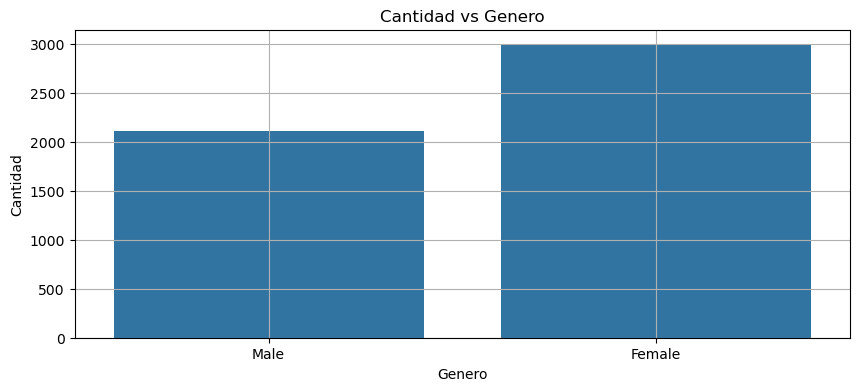

In [28]:
## GRAFICA DE GENERO

plt.figure(figsize=(10,4))
plt.title("Cantidad vs Genero")
sns.countplot(data=DataPandasB, x='Genero')
plt.xlabel("Genero")
plt.ylabel("Cantidad")
plt.grid()
plt.show()

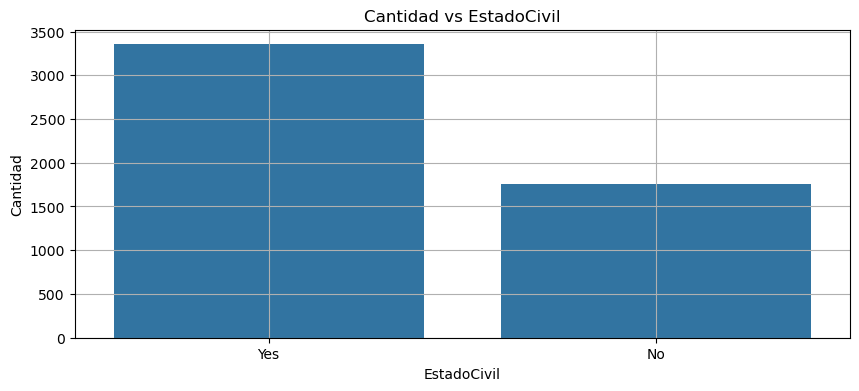

In [29]:
## GRAFICA DE ESTADO CIVIL

plt.figure(figsize=(10,4))
plt.title("Cantidad vs EstadoCivil")
sns.countplot(data=DataPandasB, x='EstadoCivil')
plt.xlabel("EstadoCivil")
plt.ylabel("Cantidad")
plt.grid()
plt.show()

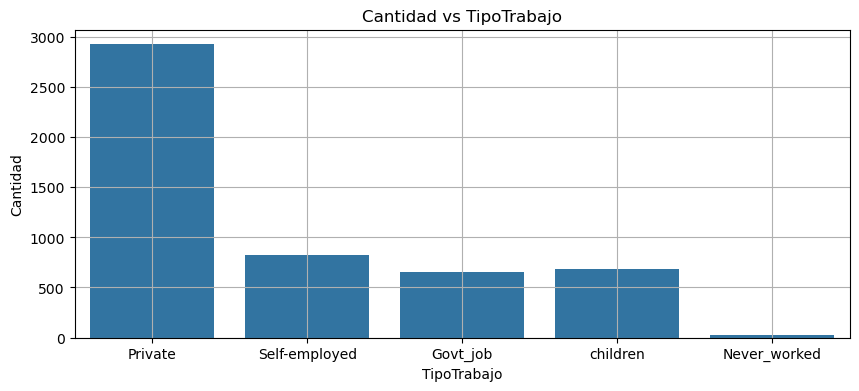

In [30]:
## GRAFICA DE TIPO TRABAJO

plt.figure(figsize=(10,4))
plt.title("Cantidad vs TipoTrabajo")
sns.countplot(data=DataPandasB, x='TipoTrabajo')
plt.xlabel("TipoTrabajo")
plt.ylabel("Cantidad")
plt.grid()
plt.show()

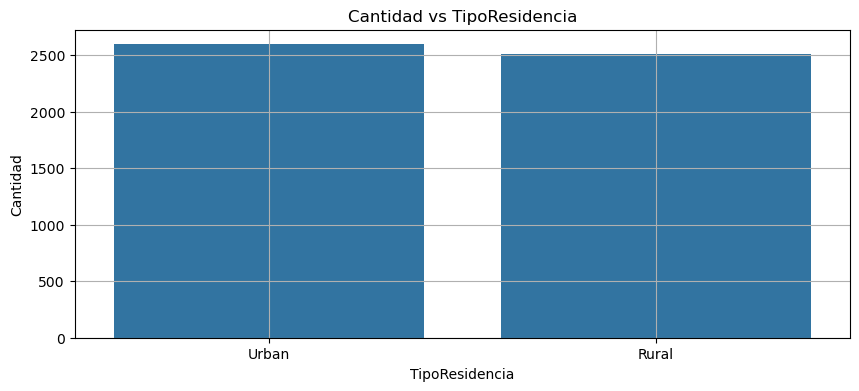

In [31]:
## GRAFICA DE TIPO RESIDENCIA

plt.figure(figsize=(10,4))
plt.title("Cantidad vs TipoResidencia")
sns.countplot(data=DataPandasB, x='TipoResidencia')
plt.xlabel("TipoResidencia")
plt.ylabel("Cantidad")
plt.grid()
plt.show()

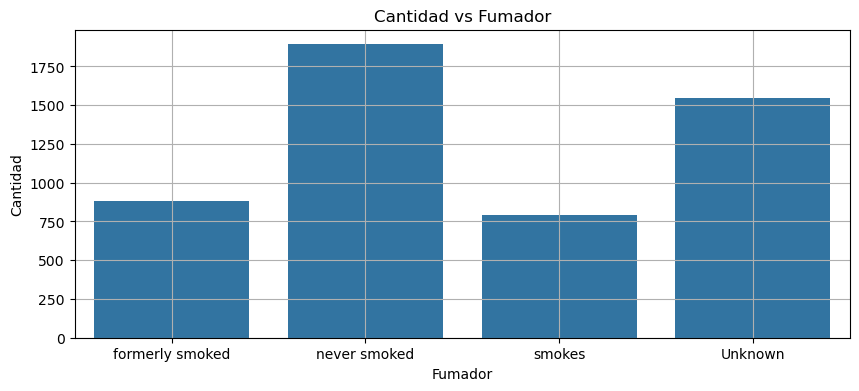

In [32]:
## GRAFICA DE TIPO TRABAJO

plt.figure(figsize=(10,4))
plt.title("Cantidad vs Fumador")
sns.countplot(data=DataPandasB, x='Fumador')
plt.xlabel("Fumador")
plt.ylabel("Cantidad")
plt.grid()
plt.show()

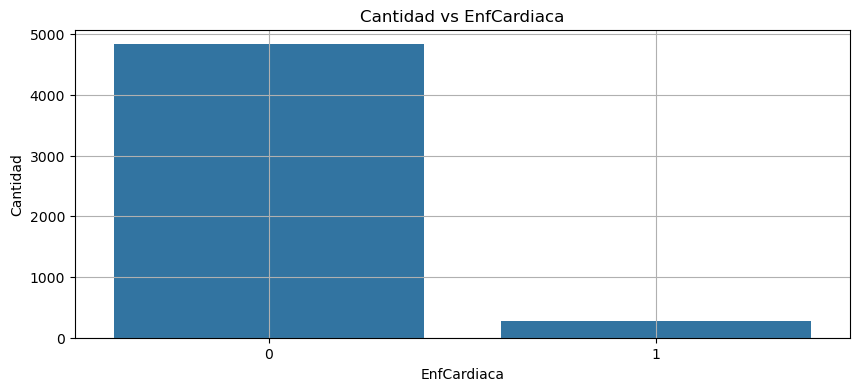

In [33]:
plt.figure(figsize=(10,4))
plt.title("Cantidad vs EnfCardiaca")
sns.countplot(data=DataPandasB, x='EnfCardiaca')
plt.xlabel("EnfCardiaca")
plt.ylabel("Cantidad")
plt.grid()
plt.show()

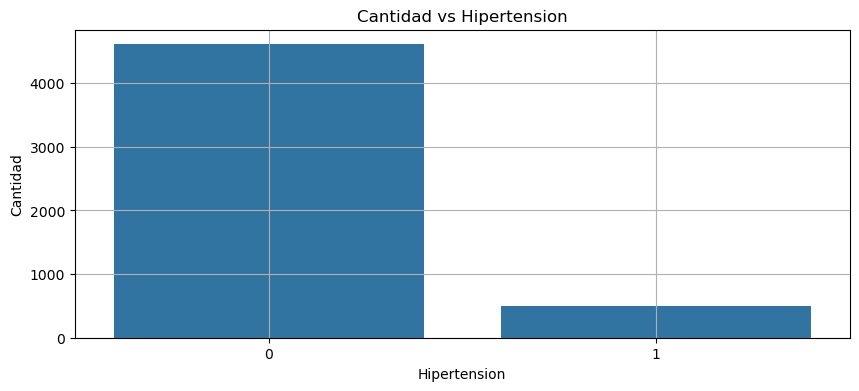

In [34]:
plt.figure(figsize=(10,4))
plt.title("Cantidad vs Hipertension")
sns.countplot(data=DataPandasB, x='Hipertension')
plt.xlabel("Hipertension")
plt.ylabel("Cantidad")
plt.grid()
plt.show()

**Análisis de variables cualitativas**
- **Género:** hay más mujeres (2 994, ~58.6 %) que hombres (2 115, ~41.4 %). El desbalance es moderado y no impide usar la variable. El único registro "Other" se eliminó porque una sola observación no permite generalizar.
- **Estado civil:** la mayoría ha estado casada alguna vez (3 353, ~65.6 %) frente a 1 757 que no (~34.4 %). Esta variable está muy ligada a la edad, ya que casi todos los menores aparecen como "No". Por eso puede actuar como un indicador indirecto de la edad más que como un factor de riesgo propio.
- **Tipo de trabajo:** predomina el sector privado (2 925, ~57.2 %), seguido de independientes (819, ~16 %), niños (687, ~13.4 %) y empleados públicos (657, ~12.9 %). "Never_worked" es casi inexistente (22, ~0.4 %), por lo que se recomienda agruparla con "children" para no crear una categoría con muy poca información al codificar.
- **Tipo de residencia:** urbana (2 596, ~50.8 %) y rural (2 514, ~49.2 %) están prácticamente equilibradas.
- **Fumador:** la categoría más frecuente es "never smoked" (1 892, ~37 %), pero "Unknown" ocupa el segundo lugar (1 544, ~30.2 %). En la práctica es un valor faltante disfrazado, y muchos de esos registros probablemente son niños. Se mantiene como categoría propia, porque eliminar el 30 % del dataset afectaría a la clase minoritaria. Fumadores actuales (789, ~15.4 %) y exfumadores (885, ~17.3 %) suman cerca de un tercio de la muestra.
- **Hipertensión:** solo ~9.7 % de los pacientes (≈ 500) tiene hipertensión. Es una variable muy desbalanceada, pero es un factor de riesgo clínico conocido del ictus, así que se espera que tenga peso en el modelo pese a su baja frecuencia.
- **Enfermedad cardiaca:** aún más desbalanceada, con solo ~5.4 % (≈ 275) de pacientes con enfermedad cardiaca. Igual que la hipertensión, su baja frecuencia no le quita relevancia clínica.

# Graficas sovre datos generales de Pacientes CUANTITATIVAS

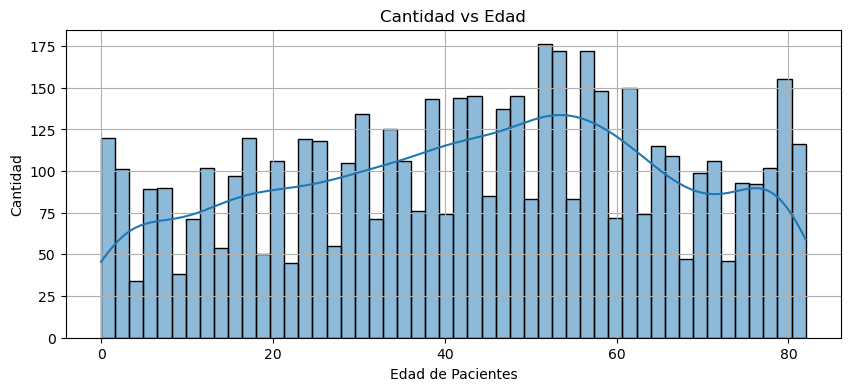

In [35]:
plt.figure(figsize=(10,4))
plt.title("Cantidad vs Edad")
sns.histplot(data=DataPandasB, x='Edad', bins=50, kde=True)
plt.xlabel("Edad de Pacientes")
plt.ylabel("Cantidad")
plt.grid()
plt.show()

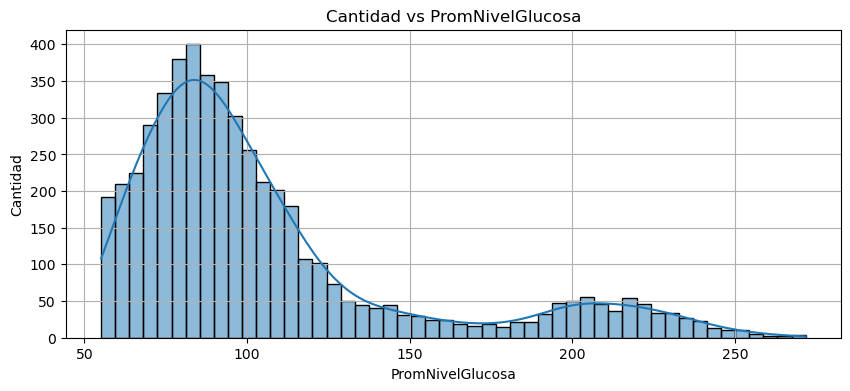

In [36]:
plt.figure(figsize=(10,4))
plt.title("Cantidad vs PromNivelGlucosa")
sns.histplot(data=DataPandasB, x='PromNivelGlucosa', bins=50, kde=True)
plt.xlabel("PromNivelGlucosa")
plt.ylabel("Cantidad")
plt.grid()
plt.show()

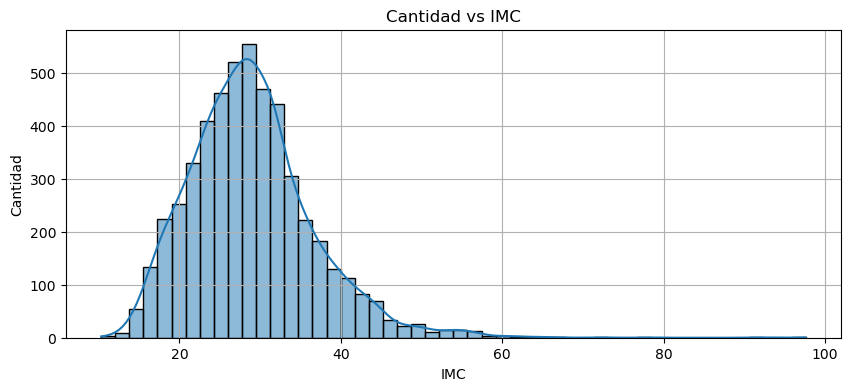

In [37]:
plt.figure(figsize=(10,4))
plt.title("Cantidad vs IMC")
sns.histplot(data=DataPandasB, x='IMC', bins=50, kde=True)
plt.xlabel("IMC")
plt.ylabel("Cantidad")
plt.grid()
plt.show()

**Análisis de variables cuantitativas**
- **Edad:** cubre de 0 a 82 años con una distribución amplia y sin un pico dominante. Hay más pacientes entre los 40 y 60 años y un grupo grande cerca de los 80. Al convertir la edad a entero, los bebés menores de un año (que venían con edades decimales) quedaron en 0.
- **Nivel promedio de glucosa:** la distribución es **bimodal y sesgada a la derecha**. La mayoría se concentra entre 70 y 110 mg/dL, con un pico cerca de 85. Hay un segundo grupo más pequeño alrededor de 200–230 mg/dL, valores compatibles con diabetes o hiperglucemia. Ese segundo grupo es clínicamente relevante y no debe tratarse como atípico.
- **IMC:** la distribución es aproximadamente normal con cola a la derecha, centrada cerca de 28 (sobrepeso). La mayoría está entre 18 y 40. Hay valores extremos por encima de 60 (máximo cercano a 97) que son poco plausibles y probablemente errores de registro. Se puede evaluar recortarlos (por ejemplo a 60). La imputación por género y edad no generó picos artificiales visibles.
- **Escala:** las tres variables tienen rangos muy distintos, por lo que se recomienda estandarizarlas (StandardScaler en Spark ML) antes de entrenar modelos sensibles a la escala.

# Graficas sobre datos generales de Pacientes: CUANTITATIVAS con DERRAME

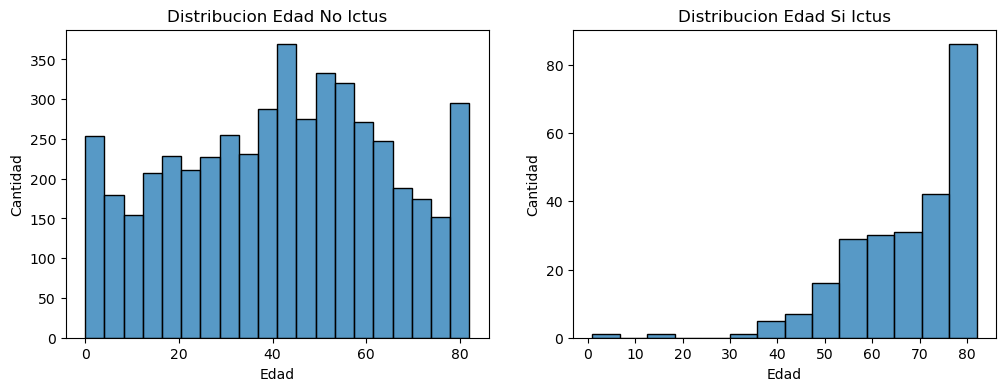

In [38]:
fig, ejes = plt.subplots(1,2, figsize=(12,4))
ejes[0].set_title('Distribucion Edad No Ictus')
ejes[0].set_ylabel('Cantidad')
eje0 = sns.histplot(data=DataPandasB.loc[DataPandasB['ICTUS'] == 0], x='Edad', ax=ejes[0])
ejes[1].set_title('Distribucion Edad Si Ictus')
ejes[1].set_ylabel('Cantidad')
eje1 = sns.histplot(data=DataPandasB.loc[DataPandasB['ICTUS'] == 1], x='Edad', ax=ejes[1])

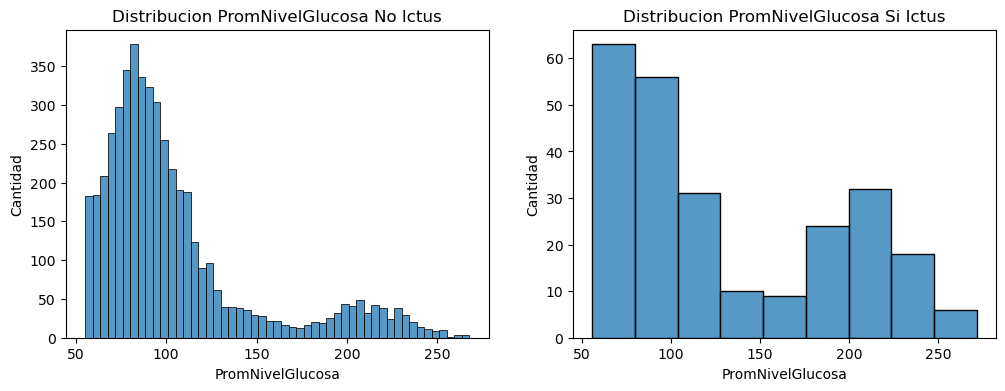

In [39]:
fig, ejes = plt.subplots(1,2, figsize=(12,4))
ejes[0].set_title('Distribucion PromNivelGlucosa No Ictus')
ejes[0].set_ylabel('Cantidad')
eje0 = sns.histplot(data=DataPandasB.loc[DataPandasB['ICTUS'] == 0], x='PromNivelGlucosa', ax=ejes[0])
ejes[1].set_title('Distribucion PromNivelGlucosa Si Ictus')
ejes[1].set_ylabel('Cantidad')
eje1 = sns.histplot(data=DataPandasB.loc[DataPandasB['ICTUS'] == 1], x='PromNivelGlucosa', ax=ejes[1])

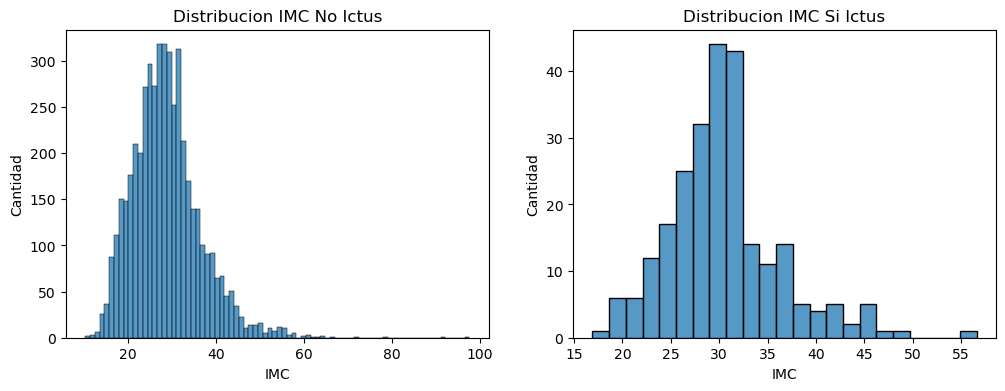

In [40]:
fig, ejes = plt.subplots(1,2, figsize=(12,4))
ejes[0].set_title('Distribucion IMC No Ictus')
ejes[0].set_ylabel('Cantidad')
eje0 = sns.histplot(data=DataPandasB.loc[DataPandasB['ICTUS'] == 0], x='IMC', ax=ejes[0])
ejes[1].set_title('Distribucion IMC Si Ictus')
ejes[1].set_ylabel('Cantidad')
eje1 = sns.histplot(data=DataPandasB.loc[DataPandasB['ICTUS'] == 1], x='IMC', ax=ejes[1])

# Analisis

**Análisis de variables cuantitativas frente al ICTUS**
- **Desbalance de clases:** las escalas del eje Y lo muestran claramente. El grupo sin ictus llega a cientos de pacientes por barra, mientras que el grupo con ictus llega apenas a decenas (≈ 249 casos en total, ~4.9 % del dataset). Es un desbalance severo: un modelo que siempre prediga "No" tendría ~95 % de exactitud sin detectar ningún caso. Por eso la evaluación debe basarse en *recall*, *precision*, F1 y AUC de la clase 1, y el entrenamiento debe considerar técnicas de balanceo (pesos por clase, submuestreo o sobremuestreo).
- **Edad, la variable más discriminante:** en los pacientes sin ictus la edad se reparte en todo el rango de 0 a 82 años. En los pacientes con ictus casi todos los casos aparecen después de los 40, crecen de forma sostenida con la edad y se concentran sobre todo entre 75 y 82 años. Solo hay un par de casos aislados en menores de 20. La edad es el factor de riesgo más claro del dataset.
- **Glucosa:** en el grupo sin ictus predomina el pico normal (70–110 mg/dL) y el grupo de glucosa alta (~200+) es pequeño en proporción. En el grupo con ictus ese segundo grupo pesa mucho más, porque una parte importante de los casos está entre 175 y 250 mg/dL. La glucosa elevada se asocia con mayor riesgo de ictus.
- **IMC:** ambas distribuciones tienen forma parecida. En el grupo con ictus el IMC se concentra alrededor de 28–32, algo por encima del grupo sin ictus, y no aparece ninguno de los valores extremos (> 60). La diferencia es pequeña, así que el IMC parece ser un predictor más débil que la edad y la glucosa.
- **Nota:** como las escalas del eje Y son muy distintas entre ambos grupos, las comparaciones se hacen sobre la **forma** de cada distribución, no sobre la altura de las barras.

## 2. Preparación de datos
### 2.1 Tratamiento de valores extremos del IMC

En el análisis exploratorio se vio que hay IMC por encima de 60 (máximo cercano a 97). Son valores poco
plausibles y probablemente errores de registro, así que se **recortan a 60** (*capping*). Así no se pierden
registros y se reduce el efecto de esos extremos en los modelos sensibles a la escala.

In [ ]:
### Cantidad de pacientes con IMC > 60 antes del recorte
print("Pacientes con IMC > 60:", df04.where(F.col('IMC') > 60).count())

### Se recorta el IMC a 60
df04 = df04.withColumn('IMC', F.when(F.col('IMC') > 60, 60.0).otherwise(F.col('IMC')))

### Se verifica
df04.select(F.min('IMC'), F.max('IMC'), F.mean('IMC')).show()

### 2.2 Variable derivada: AltoRiesgo

In [41]:
##Se añade nueva columna AltoRIesgo: Edad>41 y PromNivelGucosa<127
df05 = df04.withColumn('AltoRiesgo', F.when((F.col('Edad')>41) &
                                            (F.col('PromNivelGlucosa')<127),1).otherwise(0))

# Se observa el dataframe
df05.show(5)

+-----+------+----+------------+-----------+-----------+-------------+--------------+----------------+------------------+---------------+-----+----------+
|   id|Genero|Edad|Hipertension|EnfCardiaca|EstadoCivil|  TipoTrabajo|TipoResidencia|PromNivelGlucosa|               IMC|        Fumador|ICTUS|AltoRiesgo|
+-----+------+----+------------+-----------+-----------+-------------+--------------+----------------+------------------+---------------+-----+----------+
| 9046|  Male|  67|           0|          1|        Yes|      Private|         Urban|          228.69|36.599998474121094|formerly smoked|    1|         0|
|51676|Female|  61|           0|          0|        Yes|Self-employed|         Rural|          202.21|             30.78|   never smoked|    1|         0|
|31112|  Male|  80|           0|          1|        Yes|      Private|         Rural|          105.92|              32.5|   never smoked|    1|         1|
|60182|Female|  49|           0|          0|        Yes|      Private|

In [42]:
dataPandas1 = df05.toPandas()

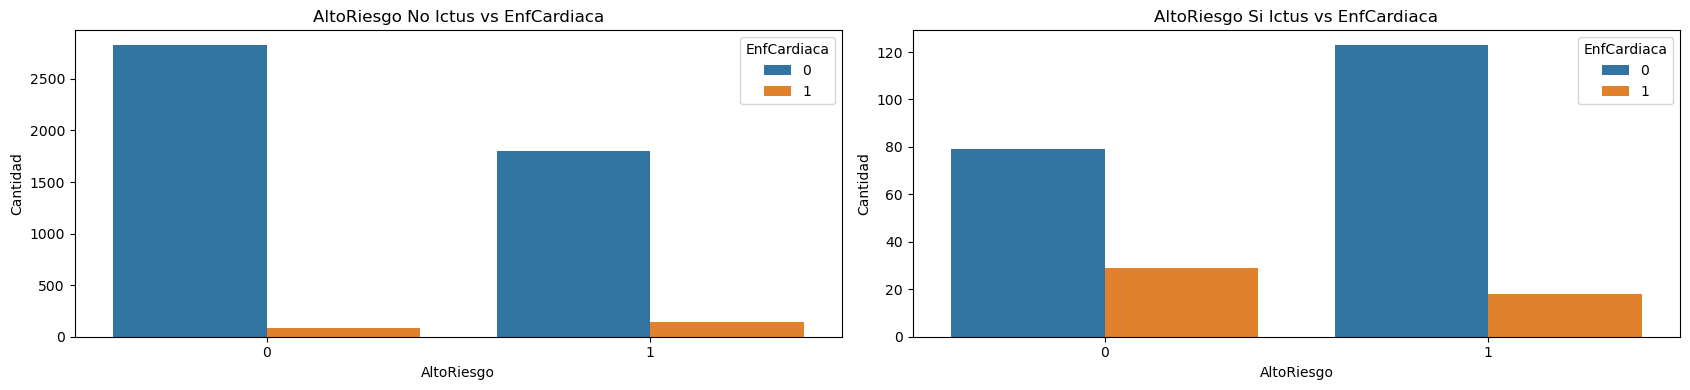

In [43]:
### AltoRiesgo vs EnfCardiaca, separado por ICTUS
fig, ejes = plt.subplots(1, 2, figsize=(17,4))

ejes[0].set_title('AltoRiesgo No Ictus vs EnfCardiaca')
sns.countplot(data=dataPandas1.loc[dataPandas1['ICTUS'] == 0], x='AltoRiesgo', hue='EnfCardiaca', ax=ejes[0])
ejes[0].set_ylabel('Cantidad')

ejes[1].set_title('AltoRiesgo Si Ictus vs EnfCardiaca')
sns.countplot(data=dataPandas1.loc[dataPandas1['ICTUS'] == 1], x='AltoRiesgo', hue='EnfCardiaca', ax=ejes[1])
ejes[1].set_ylabel('Cantidad')

plt.tight_layout()
plt.show()

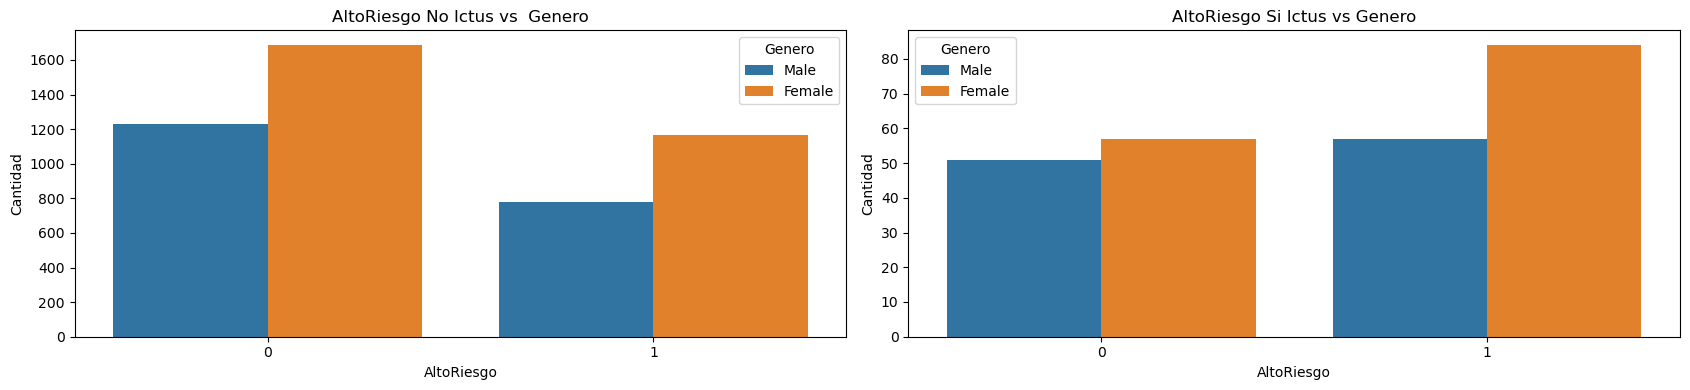

In [44]:
### AltoRiesgo vs EnfCardiaca, separado por ICTUS
fig, ejes = plt.subplots(1, 2, figsize=(17,4))

ejes[0].set_title('AltoRiesgo No Ictus vs  Genero')
sns.countplot(data=dataPandas1.loc[dataPandas1['ICTUS'] == 0], x='AltoRiesgo', hue='Genero', ax=ejes[0])
ejes[0].set_ylabel('Cantidad')

ejes[1].set_title('AltoRiesgo Si Ictus vs Genero')
sns.countplot(data=dataPandas1.loc[dataPandas1['ICTUS'] == 1], x='AltoRiesgo', hue='Genero', ax=ejes[1])
ejes[1].set_ylabel('Cantidad')

plt.tight_layout()
plt.show()

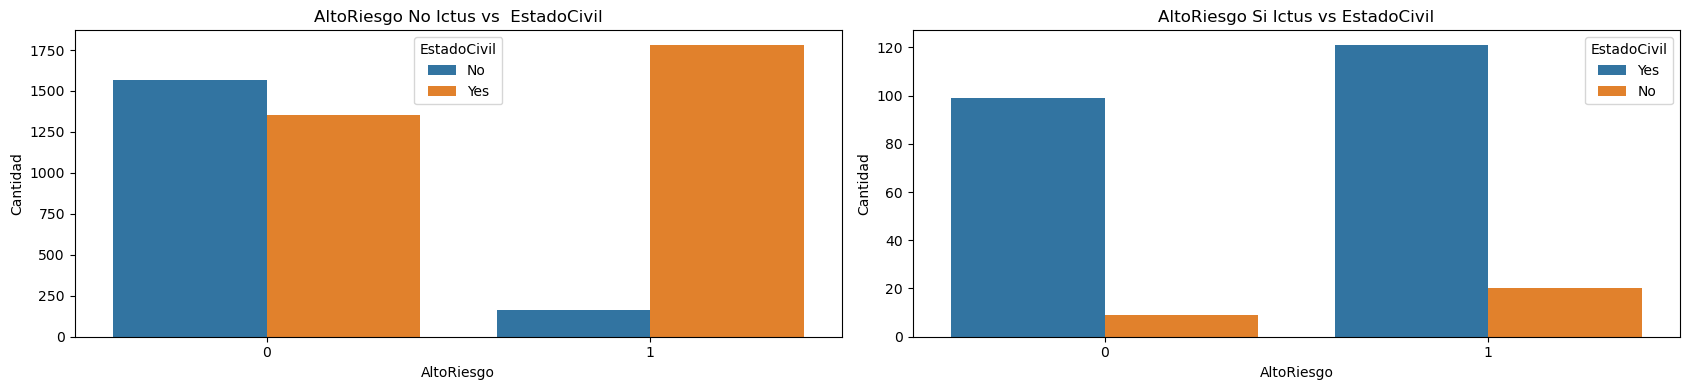

In [45]:
### AltoRiesgo vs EnfCardiaca, separado por ICTUS
fig, ejes = plt.subplots(1, 2, figsize=(17,4))

ejes[0].set_title('AltoRiesgo No Ictus vs  EstadoCivil')
sns.countplot(data=dataPandas1.loc[dataPandas1['ICTUS'] == 0], x='AltoRiesgo', hue='EstadoCivil', ax=ejes[0])
ejes[0].set_ylabel('Cantidad')

ejes[1].set_title('AltoRiesgo Si Ictus vs EstadoCivil')
sns.countplot(data=dataPandas1.loc[dataPandas1['ICTUS'] == 1], x='AltoRiesgo', hue='EstadoCivil', ax=ejes[1])
ejes[1].set_ylabel('Cantidad')

plt.tight_layout()
plt.show()

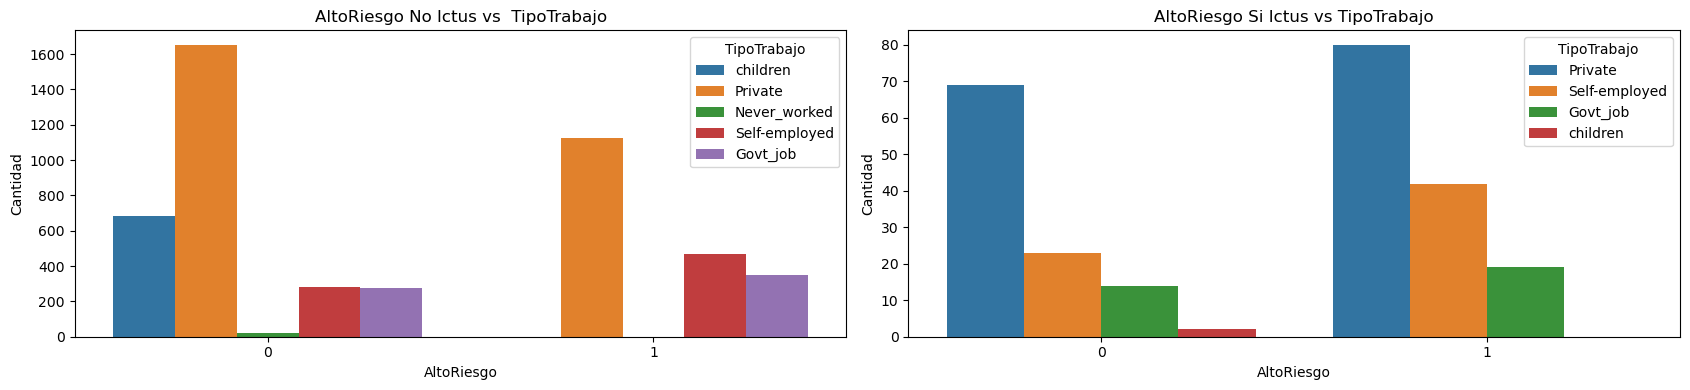

In [46]:
### AltoRiesgo vs EnfCardiaca, separado por ICTUS
fig, ejes = plt.subplots(1, 2, figsize=(17,4))

ejes[0].set_title('AltoRiesgo No Ictus vs  TipoTrabajo')
sns.countplot(data=dataPandas1.loc[dataPandas1['ICTUS'] == 0], x='AltoRiesgo', hue='TipoTrabajo', ax=ejes[0])
ejes[0].set_ylabel('Cantidad')

ejes[1].set_title('AltoRiesgo Si Ictus vs TipoTrabajo')
sns.countplot(data=dataPandas1.loc[dataPandas1['ICTUS'] == 1], x='AltoRiesgo', hue='TipoTrabajo', ax=ejes[1])
ejes[1].set_ylabel('Cantidad')

plt.tight_layout()
plt.show()

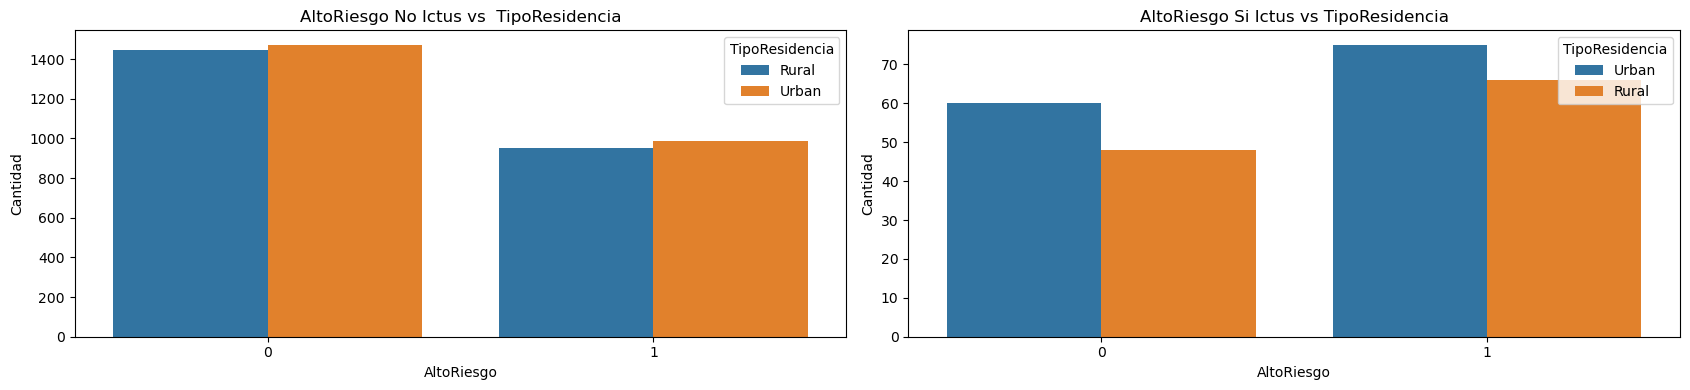

In [47]:
### AltoRiesgo vs EnfCardiaca, separado por ICTUS
fig, ejes = plt.subplots(1, 2, figsize=(17,4))

ejes[0].set_title('AltoRiesgo No Ictus vs  TipoResidencia')
sns.countplot(data=dataPandas1.loc[dataPandas1['ICTUS'] == 0], x='AltoRiesgo', hue='TipoResidencia', ax=ejes[0])
ejes[0].set_ylabel('Cantidad')

ejes[1].set_title('AltoRiesgo Si Ictus vs TipoResidencia')
sns.countplot(data=dataPandas1.loc[dataPandas1['ICTUS'] == 1], x='AltoRiesgo', hue='TipoResidencia', ax=ejes[1])
ejes[1].set_ylabel('Cantidad')

plt.tight_layout()
plt.show()

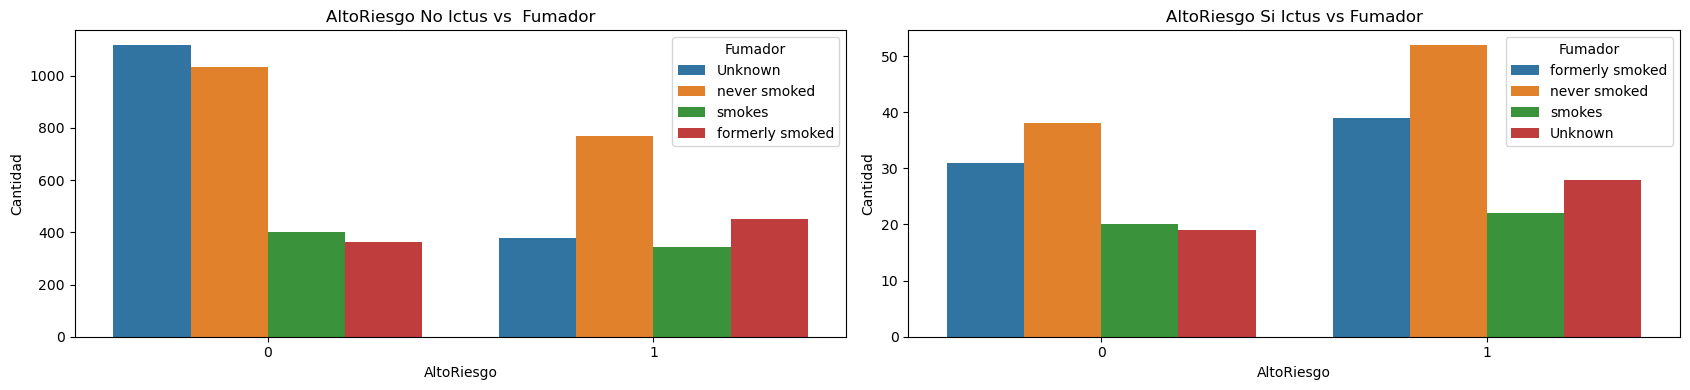

In [48]:
### AltoRiesgo vs EnfCardiaca, separado por ICTUS
fig, ejes = plt.subplots(1, 2, figsize=(17,4))

ejes[0].set_title('AltoRiesgo No Ictus vs  Fumador')
sns.countplot(data=dataPandas1.loc[dataPandas1['ICTUS'] == 0], x='AltoRiesgo', hue='Fumador', ax=ejes[0])
ejes[0].set_ylabel('Cantidad')

ejes[1].set_title('AltoRiesgo Si Ictus vs Fumador')
sns.countplot(data=dataPandas1.loc[dataPandas1['ICTUS'] == 1], x='AltoRiesgo', hue='Fumador', ax=ejes[1])
ejes[1].set_ylabel('Cantidad')

plt.tight_layout()
plt.show()

**Análisis de AltoRiesgo frente al ICTUS y las variables cualitativas**

*(Conteos aproximados leídos de las gráficas; la tasa de ICTUS se calcula sobre el total de cada categoría.)*

- **AltoRiesgo:** de los ≈ 249 casos de ictus, ≈ 141 (57 %) tienen AltoRiesgo = 1 y ≈ 108 (43 %) tienen AltoRiesgo = 0. La tasa de ictus es de ~6.8 % en AltoRiesgo = 1 frente a ~3.6 % en AltoRiesgo = 0, casi el doble. La variable sí separa algo, pero casi la mitad de los casos de ictus quedan fuera de ella. Esto pasa porque la condición `PromNivelGlucosa < 127` deja por fuera a los mayores de 41 con glucosa alta, que según el análisis anterior son justamente un grupo de riesgo. AltoRiesgo está capturando sobre todo el efecto de la **edad**.
- **Enfermedad cardiaca:** es mucho más frecuente entre quienes tuvieron ictus (≈ 47 de 249, ~19 %) que entre quienes no (~4.6 %). Llama la atención que en el grupo con ictus y AltoRiesgo = 0 ~27 % tiene enfermedad cardiaca. Ese grupo probablemente corresponde a mayores con glucosa alta, que la variable AltoRiesgo no cubre. La enfermedad cardiaca se confirma como un factor de riesgo relevante.
- **Género:** la tasa de ictus es casi igual en mujeres (~4.7 %) y hombres (~5.1 %). Hay más casos femeninos en números absolutos solo porque hay más mujeres en el dataset. El género aporta poco al modelo.
- **Estado civil:** ≈ 220 de los 249 casos (~88 %) son personas casadas alguna vez, con una tasa de ~6.6 % frente a ~1.7 % en los no casados. Como ya se mencionó, este efecto se explica por la edad: los "No" incluyen a todos los menores. En AltoRiesgo = 1 (mayores de 41) casi todos están casados.
- **Tipo de trabajo:** los independientes (Self-employed) tienen la tasa más alta (~7.9 %), seguidos de Private (~5.1 %) y Govt_job (~5.0 %). En "children" solo hay ≈ 2 casos (~0.3 %) y en "Never_worked" ninguno. Las diferencias vuelven a reflejar la edad, porque los independientes suelen ser mayores. En AltoRiesgo = 1 desaparecen "children" y "Never_worked", algo coherente con la condición Edad > 41.
- **Tipo de residencia:** las tasas son muy parecidas (urbana ~5.2 %, rural ~4.5 %) y la proporción se mantiene en ambos niveles de AltoRiesgo. Confirma que es una variable con poco poder predictivo.
- **Fumador:** los exfumadores tienen la tasa más alta (~7.9 %), seguidos de fumadores actuales (~5.3 %) y "never smoked" (~4.8 %). "Unknown" tiene la más baja (~3.0 %), lo que concuerda con que agrupe a muchos niños. Que los exfumadores superen a los fumadores actuales también se explica por la edad: suelen ser personas mayores que dejaron de fumar.

### 2.3 Codificación de las variables categóricas

1. Se elimina `id`, que solo identifica al paciente.
2. **StringIndexer** convierte cada categoría de texto en un índice numérico (`_IND`).
3. **OneHotEncoder** convierte cada índice en un vector binario (`_OHE`). Así se evita que los modelos
   lineales (RL, SVC, MLP, NB) interpreten un orden que no existe entre categorías, por ejemplo entre los tipos
   de trabajo. Se usa `dropLast=True` para no crear columnas redundantes.

In [49]:
df05.columns

['id',
 'Genero',
 'Edad',
 'Hipertension',
 'EnfCardiaca',
 'EstadoCivil',
 'TipoTrabajo',
 'TipoResidencia',
 'PromNivelGlucosa',
 'IMC',
 'Fumador',
 'ICTUS',
 'AltoRiesgo']

In [50]:
### SE observan las categorias de las variables categóricas

df05.select('Genero').distinct().show()
df05.select('EstadoCivil').distinct().show()
df05.select('TipoTrabajo').distinct().show()
df05.select('TipoResidencia').distinct().show()
df05.select('Fumador').distinct().show()

+------+
|Genero|
+------+
|Female|
|  Male|
+------+

+-----------+
|EstadoCivil|
+-----------+
|         No|
|        Yes|
+-----------+

+-------------+
|  TipoTrabajo|
+-------------+
| Never_worked|
|Self-employed|
|      Private|
|     children|
|     Govt_job|
+-------------+

+--------------+
|TipoResidencia|
+--------------+
|         Urban|
|         Rural|
+--------------+

+---------------+
|        Fumador|
+---------------+
|         smokes|
|        Unknown|
|   never smoked|
|formerly smoked|
+---------------+



In [51]:
### En primer lugar se elimina la columna id

df05 = df05.drop('id')

In [ ]:
### En segundo lugar se tratan las categorias, cambio de valores
from pyspark.ml.feature import StringIndexer, VectorAssembler, OneHotEncoder, StandardScaler
from pyspark.ml import Pipeline
from pyspark.ml.evaluation import MulticlassClassificationEvaluator, BinaryClassificationEvaluator

In [53]:
### Columnas numericas

colNumerica = ['Edad','Hipertension','EnfCardiaca',
               'PromNivelGlucosa','IMC','ICTUS','AltoRiesgo']

### Se genera indices para cada variable; se renombra con _IND
indices = [StringIndexer(inputCol=variable, outputCol=variable+'_IND').fit(df05)
           for variable in list(set(df05.columns)-set(colNumerica))
          ]

### SE GENERA UN PIPELINE
pipelineICTUS = Pipeline(stages=indices)
df06 = pipelineICTUS.fit(df05).transform(df05)
df06.show(5)

+------+----+------------+-----------+-----------+-------------+--------------+----------------+------------------+---------------+-----+----------+-----------+----------+------------------+---------------+---------------+
|Genero|Edad|Hipertension|EnfCardiaca|EstadoCivil|  TipoTrabajo|TipoResidencia|PromNivelGlucosa|               IMC|        Fumador|ICTUS|AltoRiesgo|Fumador_IND|Genero_IND|TipoResidencia_IND|TipoTrabajo_IND|EstadoCivil_IND|
+------+----+------------+-----------+-----------+-------------+--------------+----------------+------------------+---------------+-----+----------+-----------+----------+------------------+---------------+---------------+
|  Male|  67|           0|          1|        Yes|      Private|         Urban|          228.69|36.599998474121094|formerly smoked|    1|         0|        2.0|       1.0|               0.0|            0.0|            0.0|
|Female|  61|           0|          0|        Yes|Self-employed|         Rural|          202.21|            

In [54]:
varCategorias = ['Genero', 'EstadoCivil', 'TipoTrabajo', 'TipoResidencia','Fumador']
df06 = df06.drop(*varCategorias)

df06.show(5)

+----+------------+-----------+----------------+------------------+-----+----------+-----------+----------+------------------+---------------+---------------+
|Edad|Hipertension|EnfCardiaca|PromNivelGlucosa|               IMC|ICTUS|AltoRiesgo|Fumador_IND|Genero_IND|TipoResidencia_IND|TipoTrabajo_IND|EstadoCivil_IND|
+----+------------+-----------+----------------+------------------+-----+----------+-----------+----------+------------------+---------------+---------------+
|  67|           0|          1|          228.69|36.599998474121094|    1|         0|        2.0|       1.0|               0.0|            0.0|            0.0|
|  61|           0|          0|          202.21|             30.78|    1|         0|        0.0|       0.0|               1.0|            1.0|            0.0|
|  80|           0|          1|          105.92|              32.5|    1|         1|        0.0|       1.0|               1.0|            0.0|            0.0|
|  49|           0|          0|          171.2

In [ ]:
### Se aplica OneHotEncoder sobre los índices de las categóricas
colIND = ['Genero_IND', 'EstadoCivil_IND', 'TipoTrabajo_IND', 'TipoResidencia_IND', 'Fumador_IND']
colOHE = [c.replace('_IND', '_OHE') for c in colIND]

codificador = OneHotEncoder(inputCols=colIND, outputCols=colOHE, dropLast=True)
df07 = codificador.fit(df06).transform(df06).drop(*colIND)

df07.show(5, False)

### 2.4 Vector de características

MLlib necesita que todas las variables independientes estén en una sola columna de tipo vector. Se usa
**VectorAssembler** con las 6 variables numéricas o binarias y los 5 vectores one-hot. La variable objetivo
se convierte a `double`, que es el tipo que esperan los clasificadores de MLlib.

In [ ]:
### Se genera un vector con solo las variables independientes
colEntrada = ['Edad', 'Hipertension', 'EnfCardiaca', 'PromNivelGlucosa', 'IMC', 'AltoRiesgo'] + colOHE

varIndependientes = VectorAssembler(inputCols=colEntrada, outputCol='independientes')

vectorIndependientes = varIndependientes.transform(df07) \
                                        .select('independientes', F.col('ICTUS').cast('double').alias('ICTUS'))

### Nombres de cada posición del vector (útil para interpretar importancias y coeficientes)
metaAttrs = vectorIndependientes.schema['independientes'].metadata['ml_attr']['attrs']
nombresVars = [a['name'] for a in sorted(sum(metaAttrs.values(), []), key=lambda a: a['idx'])]
print(f"Número de variables en el vector: {len(nombresVars)}")
print(nombresVars)

### Se observa el vector
vectorIndependientes.show(5, False)

### 2.5 División de datos de entrenamiento y prueba (estratificada)

Se separa 80 % para entrenamiento y 20 % para prueba. La división se hace **por clase** (estratificada), así
ambos conjuntos conservan la misma proporción de ICTUS. Con tan pocos positivos, una división aleatoria simple
podría dejar el conjunto de prueba con muy pocos casos. Se fija `seed=42` para que el resultado sea
reproducible.

In [ ]:
dfML = vectorIndependientes.select(['independientes', 'ICTUS'])

### División estratificada: 80% / 20% dentro de cada clase
entreno0, prueba0 = dfML.where(F.col('ICTUS') == 0).randomSplit([0.8, 0.2], seed=42)
entreno1, prueba1 = dfML.where(F.col('ICTUS') == 1).randomSplit([0.8, 0.2], seed=42)

entrenamiento = entreno0.union(entreno1)
prueba = prueba0.union(prueba1)

In [ ]:
### Se revisa la poblacion ICTUS=1 en ambos conjuntos
for nombre, conjunto in [('entrenamiento', entrenamiento), ('prueba', prueba)]:
    total = float(conjunto.count())
    siIctus = conjunto.where('ICTUS == 1').count()
    print(f"Total pacientes en {nombre} = {int(total)} | ICTUS=1: {siIctus} ({round(siIctus/total*100, 2)} %)")

### 2.6 Tratamiento del desbalance de clases

Se usan dos estrategias según lo que permita cada algoritmo de MLlib:

- **Pesos por clase (`weightCol`)**, para RL, DT, RF, GBT, SVC y NB. Cada registro recibe un peso
  $w_c = \frac{N}{2\,N_c}$, de modo que las dos clases aportan lo mismo a la función de costo. Un paciente con
  ICTUS pesa unas 10 veces más que uno sano. No se duplican ni se eliminan datos.
- **Sobremuestreo aleatorio de la clase minoritaria**, para el Perceptrón Multicapa, porque
  `MultilayerPerceptronClassifier` no admite `weightCol`. Se muestrean con reemplazo los casos de ICTUS del
  conjunto de entrenamiento hasta igualar a la clase mayoritaria.

El balanceo se aplica **solo al entrenamiento**. El conjunto de prueba conserva la distribución real, porque
es la que el modelo encontraría en la práctica.

In [ ]:
### Pesos por clase calculados sobre el entrenamiento
N  = entrenamiento.count()
N1 = entrenamiento.where(F.col('ICTUS') == 1).count()
N0 = N - N1
peso0 = N / (2.0 * N0)
peso1 = N / (2.0 * N1)
print(f"Peso clase 0 (No ICTUS) = {round(peso0, 4)}")
print(f"Peso clase 1 (Si ICTUS) = {round(peso1, 4)}")

entrenamiento = entrenamiento.withColumn('peso', F.when(F.col('ICTUS') == 1, F.lit(peso1)).otherwise(F.lit(peso0)))
entrenamiento.groupBy('ICTUS', 'peso').count().show()

### 2.7 Estandarización de las características

Las variables tienen escalas muy distintas: edad 0–82, glucosa 55–270 y binarias 0/1. **StandardScaler**
lleva cada variable a media 0 y desviación 1 ($z = \frac{x-\mu}{\sigma}$). Esto es necesario para los modelos
basados en gradiente y en distancias o márgenes (RL, SVC, MLP). Los árboles no lo necesitan, pero tampoco
les afecta. El escalador se **ajusta solo con el entrenamiento** y luego se aplica a la prueba, para no
filtrar información del conjunto de prueba (*data leakage*).

In [ ]:
escalador = StandardScaler(inputCol='independientes', outputCol='independientesEsc',
                           withMean=True, withStd=True)
modeloEscalador = escalador.fit(entrenamiento)

entrenamiento = modeloEscalador.transform(entrenamiento).cache()
prueba        = modeloEscalador.transform(prueba).cache()

### Sobremuestreo de la clase minoritaria (solo para el MLP)
mayoritaria = entrenamiento.where(F.col('ICTUS') == 0)
minoritaria = entrenamiento.where(F.col('ICTUS') == 1)
entrenamientoSobre = mayoritaria.union(
    minoritaria.sample(withReplacement=True, fraction=N0 / N1, seed=42)).cache()

print("Entrenamiento con pesos:")
entrenamiento.groupBy('ICTUS').count().orderBy('ICTUS').show()
print("Entrenamiento sobremuestreado (MLP):")
entrenamientoSobre.groupBy('ICTUS').count().orderBy('ICTUS').show()

## 3. Modelos de MLlib

Se entrenan **7 clasificadores** de `pyspark.ml.classification`, más una línea base sin balanceo:

| # | Modelo | Familia | Balanceo | Características |
|---|---|---|---|---|
| 0 | Regresión Logística (línea base) | Lineal probabilístico | Ninguno | Escaladas |
| 1 | Regresión Logística | Lineal probabilístico | Pesos | Escaladas |
| 2 | Árbol de Decisión | Árboles (CART) | Pesos | Originales |
| 3 | Random Forest | Ensamble *bagging* | Pesos | Originales |
| 4 | Gradient-Boosted Trees | Ensamble *boosting* | Pesos | Originales |
| 5 | Linear SVC | Máximo margen (*hinge loss*) | Pesos | Escaladas |
| 6 | Perceptrón Multicapa | Red neuronal | Sobremuestreo | Escaladas |
| 7 | Naive Bayes Gaussiano | Probabilístico generativo | Pesos | Escaladas |

### 3.0 Función de evaluación común

Para comparar en igualdad de condiciones, todos los modelos se evalúan con la misma función sobre el mismo
conjunto de prueba:

- **Accuracy**: proporción total de aciertos. Con el desbalance es engañosa y se reporta solo como referencia.
- **Recall (sensibilidad) clase 1** = TP / (TP + FN): proporción de pacientes con ICTUS que el modelo detecta.
  Es la **métrica más importante** en un tamizaje médico, porque un falso negativo es un paciente en riesgo
  que no se identifica.
- **Precisión clase 1** = TP / (TP + FP): de los pacientes marcados como ICTUS, cuántos lo son de verdad.
- **F1 clase 1**: media armónica entre precisión y *recall*.
- **Especificidad** = TN / (TN + FP): proporción de pacientes sanos que se clasifican bien.
- **AUC-ROC**: capacidad de ordenar a los pacientes por riesgo, sin depender del umbral (0.5 = azar, 1 = perfecto).
- **AUC-PR**: área bajo la curva precisión–*recall*. Es más exigente que la AUC-ROC con clases
  desbalanceadas. Su valor de referencia es la prevalencia (~0.05).

In [ ]:
from pyspark.ml.functions import vector_to_array

resultados = {}      # métricas de cada modelo
puntajes   = {}      # (y_real, score) de cada modelo para las curvas ROC y PR

def evaluarModelo(prediccion, nombre):
    """Calcula las métricas, pinta la matriz de confusión y guarda los resultados del modelo."""
    evalMC = lambda metrica, **kw: MulticlassClassificationEvaluator(
        labelCol='ICTUS', predictionCol='prediction', metricName=metrica, **kw).evaluate(prediccion)
    ### Puntaje continuo: probabilidad de clase 1 si el modelo la entrega; si no (SVC), el margen
    colPuntaje = 'probability' if 'probability' in prediccion.columns else 'rawPrediction'
    evalBin = lambda metrica: BinaryClassificationEvaluator(
        labelCol='ICTUS', rawPredictionCol=colPuntaje, metricName=metrica).evaluate(prediccion)

    accuracy   = evalMC('accuracy')
    precision1 = evalMC('precisionByLabel', metricLabel=1.0)
    recall1    = evalMC('recallByLabel',    metricLabel=1.0)
    f1_1       = evalMC('fMeasureByLabel',  metricLabel=1.0)
    aucROC     = evalBin('areaUnderROC')
    aucPR      = evalBin('areaUnderPR')

    ### Matriz de confusión calculada en Spark
    matriz = np.zeros((2, 2), dtype=int)
    for real, pred, n in prediccion.groupBy('ICTUS', 'prediction').count().collect():
        matriz[int(real), int(pred)] = n
    TN, FP, FN, TP = matriz.ravel()
    especificidad = TN / (TN + FP) if (TN + FP) > 0 else 0.0

    resultados[nombre] = {'Accuracy': accuracy, 'Precision_1': precision1, 'Recall_1': recall1,
                          'F1_1': f1_1, 'Especificidad': especificidad,
                          'AUC_ROC': aucROC, 'AUC_PR': aucPR,
                          'TP': int(TP), 'FN': int(FN), 'FP': int(FP), 'TN': int(TN)}

    ### Puntaje para las curvas ROC y PR
    pdf = prediccion.select('ICTUS', vector_to_array(colPuntaje)[1].alias('score')).toPandas()
    puntajes[nombre] = (pdf['ICTUS'].values, pdf['score'].values)

    ### Se imprimen los resultados
    print(f"===== {nombre} =====")
    print(f"Accuracy             = {accuracy:.4f}")
    print(f"Precision (ICTUS=1)  = {precision1:.4f}")
    print(f"Recall    (ICTUS=1)  = {recall1:.4f}")
    print(f"F1        (ICTUS=1)  = {f1_1:.4f}")
    print(f"Especificidad        = {especificidad:.4f}")
    print(f"AUC-ROC              = {aucROC:.4f}")
    print(f"AUC-PR               = {aucPR:.4f}")

    ### Se pinta la matriz de confusión
    plt.figure(figsize=(5, 4))
    sns.heatmap(matriz, annot=True, cbar=False, fmt='d', cmap='Blues',
                xticklabels=['Predicted No Ictus', 'Predicted Ictus'],
                yticklabels=['True No Ictus', 'True Ictus'])
    plt.title(f"Matriz de confusión - {nombre}")
    plt.show()

### 3.1 Modelo RL (línea base): Regresión Logística sin balanceo

La regresión logística modela $P(y=1\mid x) = \sigma(\theta^T x) = \frac{1}{1+e^{-\theta^T x}}$ y ajusta
$\theta$ minimizando la entropía cruzada binaria. Primero se entrena **sin tratar el desbalance**, para mostrar
el problema de la exactitud: se espera una *accuracy* cercana a 0.95 con un *recall* de ICTUS cercano a cero.

In [ ]:
from pyspark.ml.classification import LogisticRegression

RLbase = LogisticRegression(featuresCol='independientesEsc', labelCol='ICTUS', maxIter=100)

modeloRLbase = RLbase.fit(entrenamiento)

### Se hacen las predicciones sobre los datos de prueba
prediccionRLbase = modeloRLbase.transform(prueba)
prediccionRLbase.select('ICTUS', 'probability', 'prediction').show(5, False)

In [ ]:
evaluarModelo(prediccionRLbase, 'RL base (sin balanceo)')

### 3.2 Modelo RL: Regresión Logística con pesos por clase

Es el mismo modelo, pero con `weightCol='peso'`: cada error sobre un paciente con ICTUS cuesta ~10 veces más.
Se añade una regularización ligera Elastic Net ($L_2$ con `regParam=0.01`) para controlar la varianza.

In [ ]:
RL = LogisticRegression(featuresCol='independientesEsc', labelCol='ICTUS', weightCol='peso',
                        maxIter=100, regParam=0.01, elasticNetParam=0.0)

modeloRL = RL.fit(entrenamiento)

### Se hacen las predicciones sobre los datos de prueba
prediccionRL = modeloRL.transform(prueba)
prediccionRL.select('ICTUS', 'probability', 'prediction').show(5, False)

In [ ]:
evaluarModelo(prediccionRL, 'Regresion Logistica')

### 3.3 Modelo DT: Árbol de Decisión

Construye particiones binarias de forma voraz (tipo CART) y elige en cada nodo el corte que más reduce la
impureza de **Gini**. Se limita la profundidad (`maxDepth=5`) y el mínimo de instancias por hoja para evitar
el sobreajuste. Usa las características originales, porque los árboles no dependen de la escala.

In [ ]:
from pyspark.ml.classification import DecisionTreeClassifier

DT = DecisionTreeClassifier(featuresCol='independientes', labelCol='ICTUS', weightCol='peso',
                            maxDepth=5, minInstancesPerNode=10, impurity='gini', seed=42)

modeloDT = DT.fit(entrenamiento)

### Se hacen las predicciones sobre los datos de prueba
prediccionDT = modeloDT.transform(prueba)
prediccionDT.select('ICTUS', 'probability', 'prediction').show(5, False)

In [ ]:
evaluarModelo(prediccionDT, 'Arbol de Decision')

### 3.4 Modelo RF: Random Forest

Ensamble de tipo **bagging**: entrena muchos árboles, cada uno sobre una muestra *bootstrap* y con un
subconjunto aleatorio de variables en cada partición (`featureSubsetStrategy='sqrt'`). Así los árboles quedan
poco correlacionados y la votación reduce la varianza. Se usan 200 árboles de profundidad máxima 6. Spark
entrena los árboles de forma distribuida.

In [ ]:
from pyspark.ml.classification import RandomForestClassifier

RF = RandomForestClassifier(featuresCol='independientes', labelCol='ICTUS', weightCol='peso',
                            numTrees=200, maxDepth=6, minInstancesPerNode=5,
                            featureSubsetStrategy='sqrt', seed=42)

modeloRF = RF.fit(entrenamiento)

### Se hacen las predicciones sobre los datos de prueba
prediccionRF = modeloRF.transform(prueba)
prediccionRF.select('ICTUS', 'probability', 'prediction').show(5, False)

In [ ]:
evaluarModelo(prediccionRF, 'Random Forest')

### 3.5 Modelo GBT: Gradient-Boosted Trees

Ensamble de tipo **boosting**: agrega árboles poco profundos uno tras otro, y cada uno se ajusta al gradiente
negativo de la pérdida logística (los pseudo-residuos) de los anteriores. Así reduce el sesgo de forma
secuencial. Se usan 100 iteraciones, profundidad 3 y tasa de aprendizaje 0.05 para no sobreajustar.

In [ ]:
from pyspark.ml.classification import GBTClassifier

GBT = GBTClassifier(featuresCol='independientes', labelCol='ICTUS', weightCol='peso',
                    maxIter=100, maxDepth=3, stepSize=0.05, subsamplingRate=0.8, seed=42)

modeloGBT = GBT.fit(entrenamiento)

### Se hacen las predicciones sobre los datos de prueba
prediccionGBT = modeloGBT.transform(prueba)
prediccionGBT.select('ICTUS', 'probability', 'prediction').show(5, False)

In [ ]:
evaluarModelo(prediccionGBT, 'GBT')

### 3.6 Modelo SVC: Máquina de Soporte Vectorial lineal

`LinearSVC` busca el hiperplano $w^T x + b = 0$ de **máximo margen** con margen suave. Minimiza la
*hinge loss* más una penalización $L_2$ (`regParam`, que cumple el papel inverso de $C$). MLlib solo ofrece
el kernel lineal y no entrega probabilidades. Para las curvas ROC y PR se usa la distancia al hiperplano
(`rawPrediction`). Como depende de distancias, usa las características escaladas.

In [ ]:
from pyspark.ml.classification import LinearSVC

SVC = LinearSVC(featuresCol='independientesEsc', labelCol='ICTUS', weightCol='peso',
                maxIter=200, regParam=0.01)

modeloSVC = SVC.fit(entrenamiento)

### Se hacen las predicciones sobre los datos de prueba
prediccionSVC = modeloSVC.transform(prueba)
prediccionSVC.select('ICTUS', 'rawPrediction', 'prediction').show(5, False)

In [ ]:
evaluarModelo(prediccionSVC, 'Linear SVC')

### 3.7 Modelo MPC: Perceptrón Multicapa

Red neuronal *feed-forward* con activación sigmoide en las capas ocultas y *softmax* en la salida. Se entrena
con L-BFGS por retropropagación. La capa de entrada tiene tantas neuronas como variables tiene el vector (se
calcula de forma automática después del one-hot), luego vienen dos capas ocultas de 8 y 4 neuronas, y una
salida de 2 clases. Como no admite `weightCol`, se entrena con el conjunto **sobremuestreado**.

In [ ]:
from pyspark.ml.classification import MultilayerPerceptronClassifier

nVars = len(nombresVars)
capas = [nVars, 8, 4, 2]
print(f"Arquitectura del MLP: {capas}")

MPC = MultilayerPerceptronClassifier(featuresCol='independientesEsc', labelCol='ICTUS',
                                     layers=capas, maxIter=200, blockSize=128, seed=42)

### Se entrena el modelo con el conjunto sobremuestreado
modeloMPC = MPC.fit(entrenamientoSobre)

### Se hacen las predicciones sobre los datos de prueba
prediccionMPC = modeloMPC.transform(prueba)
prediccionMPC.select('ICTUS', 'probability', 'prediction').show(5, False)

In [ ]:
evaluarModelo(prediccionMPC, 'Perceptron Multicapa')

### 3.8 Modelo NB: Naive Bayes Gaussiano

Es un clasificador generativo. Aplica el teorema de Bayes suponiendo que las variables son independientes
dado la clase, y modela cada una con una distribución normal:
$P(y\mid x) \propto P(y)\prod_j \mathcal{N}(x_j;\mu_{jy},\sigma_{jy})$. Es muy rápido y sirve como referencia
simple frente a los demás modelos.

In [ ]:
from pyspark.ml.classification import NaiveBayes

NB = NaiveBayes(featuresCol='independientesEsc', labelCol='ICTUS', weightCol='peso',
                modelType='gaussian')

modeloNB = NB.fit(entrenamiento)

### Se hacen las predicciones sobre los datos de prueba
prediccionNB = modeloNB.transform(prueba)
prediccionNB.select('ICTUS', 'probability', 'prediction').show(5, False)

In [ ]:
evaluarModelo(prediccionNB, 'Naive Bayes')

## 4. Evaluación de modelos
### 4.1 Tabla comparativa de métricas (conjunto de prueba)

In [ ]:
tablaResultados = pd.DataFrame(resultados).T
tablaResultados = tablaResultados[['Accuracy', 'Precision_1', 'Recall_1', 'F1_1', 'Especificidad',
                                   'AUC_ROC', 'AUC_PR', 'TP', 'FN', 'FP', 'TN']]
tablaResultados[['TP', 'FN', 'FP', 'TN']] = tablaResultados[['TP', 'FN', 'FP', 'TN']].astype(int)
tablaResultados = tablaResultados.sort_values('AUC_ROC', ascending=False)
tablaResultados.round(4)

### 4.2 Comparación gráfica de las métricas principales

In [ ]:
metricasGraf = ['Recall_1', 'Precision_1', 'F1_1', 'Especificidad', 'AUC_ROC', 'AUC_PR']
ax = tablaResultados[metricasGraf].plot(kind='bar', figsize=(15, 5), width=0.8)
plt.title('Métricas por modelo (conjunto de prueba)')
plt.ylabel('Valor')
plt.xticks(rotation=20, ha='right')
plt.ylim(0, 1.05)
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.25), ncol=len(metricasGraf))
plt.grid(axis='y')
plt.tight_layout()
plt.show()

### 4.3 Curvas ROC y Precisión–Recall

Las curvas muestran el comportamiento de cada modelo **para todos los umbrales posibles** y no solo para el
umbral por defecto de 0.5. La línea punteada es el clasificador aleatorio: la diagonal en ROC y la
prevalencia en PR.

In [ ]:
from sklearn.metrics import roc_curve, precision_recall_curve, auc

fig, ejes = plt.subplots(1, 2, figsize=(16, 6))
for nombre, (yReal, score) in puntajes.items():
    fpr, tpr, _ = roc_curve(yReal, score)
    ejes[0].plot(fpr, tpr, label=f"{nombre} (AUC={auc(fpr, tpr):.3f})")
    prec, rec, _ = precision_recall_curve(yReal, score)
    ejes[1].plot(rec, prec, label=f"{nombre} (AUC={auc(rec, prec):.3f})")

ejes[0].plot([0, 1], [0, 1], 'k--', label='Azar')
ejes[0].set_title('Curva ROC'); ejes[0].set_xlabel('Tasa de falsos positivos (1 - Especificidad)')
ejes[0].set_ylabel('Tasa de verdaderos positivos (Recall)'); ejes[0].legend(fontsize=9); ejes[0].grid()

prevalencia = np.mean(next(iter(puntajes.values()))[0])
ejes[1].axhline(prevalencia, color='k', linestyle='--', label=f'Azar (prevalencia={prevalencia:.3f})')
ejes[1].set_title('Curva Precisión-Recall'); ejes[1].set_xlabel('Recall')
ejes[1].set_ylabel('Precisión'); ejes[1].legend(fontsize=9); ejes[1].grid()
plt.tight_layout()
plt.show()

### 4.4 Interpretabilidad: importancia de variables y coeficientes

- En **RF** y **GBT** la importancia de cada variable es la reducción total de impureza que logra en todos
  los árboles, normalizada.
- En la **Regresión Logística** los coeficientes se calcularon sobre variables estandarizadas, así que se
  pueden comparar entre sí. Un coeficiente positivo aumenta el riesgo estimado de ICTUS y uno negativo lo
  disminuye.

In [ ]:
importancias = pd.DataFrame({
    'Random Forest': modeloRF.featureImportances.toArray(),
    'GBT':           modeloGBT.featureImportances.toArray(),
}, index=nombresVars)
coeficientesRL = pd.Series(modeloRL.coefficients.toArray(), index=nombresVars)

fig, ejes = plt.subplots(1, 2, figsize=(17, 6))
importancias.sort_values('Random Forest').plot(kind='barh', ax=ejes[0])
ejes[0].set_title('Importancia de variables (RF y GBT)'); ejes[0].grid(axis='x')

coeficientesRL.sort_values().plot(kind='barh', ax=ejes[1],
                                  color=['tab:red' if v < 0 else 'tab:blue' for v in coeficientesRL.sort_values()])
ejes[1].set_title('Coeficientes de la Regresión Logística (variables estandarizadas)'); ejes[1].grid(axis='x')
plt.tight_layout()
plt.show()

importancias.sort_values('Random Forest', ascending=False).round(4)

### 4.5 Ajuste del umbral de decisión (mejor modelo por AUC-ROC)

El umbral de 0.5 no tiene por qué ser el mejor. Se toma el modelo con mayor AUC-ROC y se recorren varios
umbrales para ver cómo se intercambian el *recall* y la precisión. En un tamizaje clínico se prefiere un
umbral que mantenga un *recall* alto, aunque eso traiga más falsos positivos.

In [ ]:
mejorModelo = tablaResultados.drop('RL base (sin balanceo)', errors='ignore')['AUC_ROC'].idxmax()
yReal, score = puntajes[mejorModelo]
print(f"Modelo analizado: {mejorModelo}")

### Si el modelo entrega márgenes (SVC) los umbrales se toman de los cuantiles del puntaje
umbrales = np.round(np.arange(0.1, 0.95, 0.1), 2) if score.min() >= 0 and score.max() <= 1 \
           else np.quantile(score, np.arange(0.1, 0.95, 0.1))

filas = []
for u in umbrales:
    yPred = (score >= u).astype(int)
    TP = int(((yPred == 1) & (yReal == 1)).sum()); FN = int(((yPred == 0) & (yReal == 1)).sum())
    FP = int(((yPred == 1) & (yReal == 0)).sum()); TN = int(((yPred == 0) & (yReal == 0)).sum())
    rec = TP / (TP + FN) if TP + FN else 0; pre = TP / (TP + FP) if TP + FP else 0
    filas.append({'Umbral': round(float(u), 3), 'Recall_1': rec, 'Precision_1': pre,
                  'F1_1': 2*pre*rec/(pre+rec) if pre + rec else 0,
                  'Especificidad': TN / (TN + FP), 'TP': TP, 'FN': FN, 'FP': FP})
pd.DataFrame(filas).round(4)

## 5. Análisis de Resultados

In [ ]:
### Resumen automático a partir de la tabla de resultados
balanceados = tablaResultados.drop('RL base (sin balanceo)', errors='ignore')
base = resultados['RL base (sin balanceo)']

print(f"Línea base sin balanceo -> Accuracy = {base['Accuracy']:.3f}, Recall ICTUS = {base['Recall_1']:.3f}, "
      f"TP = {base['TP']} de {base['TP'] + base['FN']} casos")
print()
for metrica in ['Recall_1', 'Precision_1', 'F1_1', 'AUC_ROC', 'AUC_PR', 'Especificidad']:
    mejor = balanceados[metrica].idxmax()
    print(f"Mejor {metrica:<13}: {mejor:<22} ({balanceados.loc[mejor, metrica]:.3f})")
print()
print("Ranking por AUC-ROC:")
print(balanceados[['AUC_ROC', 'AUC_PR', 'Recall_1', 'Precision_1', 'F1_1']].round(3).to_string())

**1. La exactitud engaña con clases desbalanceadas.** La Regresión Logística sin balanceo obtiene una
*accuracy* cercana al 95 %, pero detecta muy pocos casos de ICTUS o ninguno. Esa exactitud coincide con la
proporción de pacientes sanos: el modelo aprende a responder casi siempre "No". Las métricas *weighted* que
se usaban en la versión preliminar del laboratorio (precisión y *recall* ponderados de ~0.90–0.95) ocultaban
el problema, porque las domina la clase mayoritaria. Por eso la comparación se hace con las métricas de la
clase 1 y con AUC.

**2. El balanceo cambia el comportamiento de los modelos.** Con pesos por clase o con sobremuestreo, todos
los modelos pasan a detectar una parte importante de los pacientes con ICTUS, es decir, el *recall* sube de
forma notable. A cambio aumentan los falsos positivos y bajan la precisión y la especificidad. Este
intercambio es esperable y, en un tamizaje médico, aceptable: es preferible enviar a valoración a un paciente
sano que dejar sin detectar a uno con riesgo.

**3. Precisión baja en todos los modelos.** Con una prevalencia de ~5 %, incluso un buen modelo genera
varios falsos positivos por cada verdadero positivo. Por eso la precisión de la clase 1 y la AUC-PR son
bajas en términos absolutos. Para valorarlas hay que compararlas con la referencia del azar (≈ 0.05): un
modelo con AUC-PR de 0.15–0.25 identifica de 3 a 5 veces mejor que una selección aleatoria.

**4. Comparación entre familias de modelos (ver tabla 4.1 y curvas 4.3).**
- Los **modelos lineales** (Regresión Logística y Linear SVC) obtienen AUC-ROC competitivas. Con pocas
  variables y una relación casi monótona con el riesgo (más edad y más glucosa implican más riesgo), una
  frontera lineal es suficiente.
- **Random Forest** y **GBT** alcanzan una capacidad de ordenamiento similar a la de los lineales. Su
  ventaja frente a esos modelos es pequeña porque el dataset tiene pocas variables y pocos positivos, y no
  hay interacciones complejas que explotar.
- El **Árbol de Decisión** individual es el más inestable: produce pocos valores de probabilidad distintos
  (uno por hoja), lo que limita su AUC y lo hace sensible a la muestra.
- El **Perceptrón Multicapa** necesita sobremuestreo y más tiempo de entrenamiento, y en datos tabulares de
  este tamaño no supera claramente a la Regresión Logística.
- **Naive Bayes** suele lograr un *recall* alto con muchos falsos positivos, porque su supuesto de
  independencia no se cumple (por ejemplo, edad, estado civil y tipo de trabajo están muy correlacionados).

**5. Variables más relevantes (ver 4.4).** La **edad** es por mucho la variable más importante en RF y GBT
y tiene el coeficiente positivo más grande en la Regresión Logística. Le siguen el **nivel de glucosa**, la
**hipertensión** y la **enfermedad cardiaca**. Variables como el tipo de residencia o el género casi no
aportan. Esto coincide con el análisis exploratorio y con la evidencia médica sobre los factores de riesgo
del ictus.

**6. Umbral de decisión (ver 4.5).** Mover el umbral permite elegir el punto de operación: un umbral bajo
maximiza el *recall* para tamizaje y uno más alto mejora la precisión cuando los recursos para valorar
pacientes son limitados. La AUC-ROC resume la calidad del modelo en todos los umbrales, por eso se usa como
criterio principal de ordenamiento y el F1 o el *recall* de la clase 1 sirven como criterio de desempate.

## 6. Conclusiones

1. **Integración HPC.** El flujo completo se ejecutó sobre la infraestructura distribuida: el dataset se
   leyó desde **Hadoop HDFS** y la limpieza, la imputación, la codificación, el escalado, el entrenamiento y
   la evaluación se hicieron con **Spark DataFrames y MLlib**. Solo los resultados agregados se pasaron a
   pandas para graficar. Así, el mismo cuaderno escala a volúmenes mucho mayores sin cambiar la lógica.

2. **La preparación de datos es determinante.** Imputar el IMC por género y grupo de edad conservó los 201
   registros incompletos, entre ellos casos de ICTUS que son muy escasos. El one-hot encoding evitó imponer
   un orden falso entre categorías, y la estandarización ajustada solo con el entrenamiento evitó la fuga de
   información.

3. **El desbalance es el problema central.** Sin tratarlo, el modelo llega a ~95 % de exactitud sin detectar
   prácticamente ningún ictus. Los pesos por clase (`weightCol`) y el sobremuestreo hicieron que los modelos
   identificaran a la mayoría de los pacientes en riesgo. Esto confirma que en problemas médicos
   desbalanceados hay que evaluar con *recall*, F1, AUC-ROC y AUC-PR de la clase minoritaria, y no con la
   *accuracy*.

4. **Selección del modelo.** Se entrenaron y compararon siete modelos de MLlib. Para este problema se
   recomienda el modelo con **mejor AUC-ROC y un recall de ICTUS alto** según la tabla 4.1. Si el desempeño es
   parecido, conviene la **Regresión Logística con pesos por clase**: es rápida, estable e interpretable (sus
   coeficientes indican cuánto aporta cada factor de riesgo), lo que es valioso en un contexto clínico.
   Random Forest y GBT son buenas alternativas cuando se prioriza la capacidad predictiva sobre la
   interpretabilidad.

5. **Factores de riesgo.** Los modelos confirman lo que mostró el análisis exploratorio: la **edad**, el
   **nivel de glucosa**, la **hipertensión** y la **enfermedad cardiaca** son los principales predictores del
   ictus, mientras que el género y el tipo de residencia aportan poco.

6. **Limitaciones y trabajo futuro.**
   - Con solo ~50 casos positivos en el conjunto de prueba, las métricas de la clase 1 varían bastante según
     la partición. Una **validación cruzada estratificada** (`CrossValidator`) daría estimaciones más estables
     y permitiría ajustar hiperparámetros con `ParamGridBuilder`.
   - La imputación del IMC usó medias calculadas con todo el dataset. Lo más riguroso sería calcularlas solo
     con el entrenamiento.
   - Se pueden probar técnicas de balanceo sintético (por ejemplo, SMOTE), ajustar el umbral con un criterio
     clínico explícito y añadir otras variables médicas (colesterol, fibrilación auricular) para mejorar la
     precisión.
   - El modelo es una herramienta de **apoyo al tamizaje** y no reemplaza el diagnóstico médico.